# Simulator for the Peer Grading Mechanisms: Removing Bias and Incentivising Precision
### Study based on Chakraborty, Jindal & Nath — *Removing Bias and Incentivizing Precision in Peer-grading* (PEQA), JAIR 2024 / arXiv:1807.11657

This notebook rebuilds the comparisons done. One can run this notebook top-to-bottom cell by cell.

## Part 0 — Setup

In [1]:
import os, sys, math, time, json, zipfile, itertools, warnings, datetime
from dataclasses import dataclass, replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar, brentq
from IPython.display import display
warnings.filterwarnings("ignore")

# ------------------------------------------------------------------ switches
QUICK_MODE     = False   # True -> fewer replications (fast smoke test)
SAVE_TO_DRIVE  = False   # True -> mount Google Drive and save outputs there
SEED           = 2024

# ------------------------------------------------------------------ folders
BASE_DIR = "."
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE_DIR = "/content/drive/MyDrive"
    except Exception as e:
        print("Could not mount Drive, falling back to local folder:", e)

OUT_DIR   = os.path.join(BASE_DIR, "peer_grading_outputs")
PLOT_DIR  = os.path.join(OUT_DIR, "plots")
DATA_DIR  = os.path.join(OUT_DIR, "data")
LOG_DIR   = os.path.join(OUT_DIR, "logs")
for d in (OUT_DIR, PLOT_DIR, DATA_DIR, LOG_DIR):
    os.makedirs(d, exist_ok=True)

def savefig(name, fig=None):
    """Save the current figure into plots/ (PNG, 150 dpi) and show it."""
    fig = fig or plt.gcf()
    path = os.path.join(PLOT_DIR, f"{name}.png")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"[saved] {path}")
    plt.show()

def save_df(df, name):
    path = os.path.join(DATA_DIR, f"{name}.csv")
    df.to_csv(path, index=False)
    print(f"[saved] {path}")

def log(msg):
    stamp = datetime.datetime.now().strftime("%H:%M:%S")
    line = f"[{stamp}] {msg}"
    print(line)
    with open(os.path.join(LOG_DIR, "run_log.txt"), "a") as f:
        f.write(line + "\n")

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

# replication budgets
REPS_SWEEP = 8   if QUICK_MODE else 40     # rounds per point in the sweeps (Exp. A, B)
REPS_ENV   = 40  if QUICK_MODE else 150    # Monte-Carlo environments in the effort game / competitive grader
log(f"Output folder: {os.path.abspath(OUT_DIR)} | QUICK_MODE={QUICK_MODE}")

[17:23:09] Output folder: /content/peer_grading_outputs | QUICK_MODE=False


## Part 1 — The simulator

### 1.1 Model (the PG$_1$ model of Piech et al. 2013, made strategic as in the paper)

* There are $n$ students. Student $j$ writes paper $j$ with **true score** $y_j \sim \mathcal F(\mu, 1/\gamma)$ (here Normal, $\mu=6$, $1/\gamma = 1.5^2$). Everybody is also a **grader**.
* Grader $i$ chooses a **reliability** $\tau_i>0$ (inverse noise variance — this is her *effort*) and a **bias** $b_i$. For each paper $j$ she grades she reports

$$\tilde y^{(i)}_j \;=\; y_j + b_i + \varepsilon_{ij}, \qquad \varepsilon_{ij}\sim \mathcal N(0,\,1/\tau_i)\ \text{independent}.$$

* **Effort.** Higher $\tau_i$ costs more. We use a convex cost $c_i(\tau)=\kappa_i\tau^2/2$ per paper graded (used in Part 5/6).
* **Assignment (paper Sec. 2.3 / Algorithm 1).** The teaching staff grade $\ell$ **probe** papers (true score known). Each grader gets $K$ papers: $K/2$ probes and $K/2$ non-probes, never her own, and she **cannot tell** probes from non-probes. We need $K/2+1\le \ell \le n/(K/2+1)$.
* **Regrading (Assumption 1).** After seeing the assigned score $r_j$, a student asks for a regrade iff $r_j<y_j$; then she gets $y_j$. So the final score is $g_j=\max(r_j,y_j)$.

### 1.2 Grader types we simulate
* *honest-noisy*: $b_i\sim\mathcal N(0,s_b^2)$, noise sd $\sigma_i=1/\sqrt{\tau_i}\sim \sigma\cdot U[1-h,1+h]$ (heterogeneous precision);
* *systematic bias*: a common shift $\delta$ added to every grader (generous / harsh culture);
* *adversarial*: a fraction of graders either report a large negative shift ("grade aggressively"), always report 0, or report uniform garbage.

**Recovery error** = RMSE between the assigned score and the true score, measured on **non-probe** papers (probes get the instructor's score in PEQA, so they would flatter it).

In [2]:
@dataclass
class SimConfig:
    n: int = 60              # students = papers = graders
    K: int = 8               # papers per grader (K/2 probes + K/2 non-probes)
    n_probes: int = 12       # l ; must satisfy K/2+1 <= l <= n/(K/2+1)
    mu: float = 6.0          # prior mean of true scores
    sd_true: float = 1.5     # prior sd of true scores  (gamma = 1/sd^2)
    noise_sd: float = 0.7    # mean grader noise sd
    noise_het: float = 0.5   # noise_i = noise_sd * U[1-het, 1+het]
    bias_sd: float = 0.5     # sd of (honest) idiosyncratic biases
    bias_shift: float = 0.0  # common shift added to every grader
    adv_frac: float = 0.0    # fraction of adversarial graders
    adv_type: str = "shift"  # "shift" | "zero" | "random"
    adv_shift: float = -5.0  # bias of "shift" adversaries
    tau_floor: float = 1e-2  # numerical safety for estimated reliabilities
    tau_cap: float = 1e3
    @property
    def gamma(self): return 1.0 / self.sd_true ** 2

def make_assignment(n, K, L, rng):
    """Balanced probe / non-probe assignment. A[i, j] = True iff grader i grades paper j."""
    half = K // 2
    assert K % 2 == 0 and L >= half + 1 and L <= n // (half + 1), \
        "need K even and K/2+1 <= n_probes <= n/(K/2+1)"
    probes = np.sort(rng.choice(n, L, replace=False))
    is_probe = np.zeros(n, bool); is_probe[probes] = True
    nonprobes = np.where(~is_probe)[0]
    A = np.zeros((n, n), bool)
    load = np.zeros(n)
    for i in rng.permutation(n):
        for pool in (probes, nonprobes):
            cand = pool[pool != i]                                  # never her own paper
            order = np.lexsort((rng.random(len(cand)), load[cand])) # least-loaded first, random ties
            pick = cand[order[:half]]
            A[i, pick] = True; load[pick] += 1
    return A, is_probe

def build_reports(y, A, bias, tau, z):
    """Reports  y~[i,j] = y_j + b_i + z_ij / sqrt(tau_i)  (NaN where not assigned). z ~ N(0,1) is passed in
    explicitly so that effort experiments can reuse the SAME noise draws (common random numbers)."""
    Y = y[None, :] + bias[:, None] + z / np.sqrt(tau)[:, None]
    return np.where(A, Y, np.nan)

def generate_population(cfg, rng):
    n = cfg.n
    sigma = cfg.noise_sd * rng.uniform(1 - cfg.noise_het, 1 + cfg.noise_het, n)
    tau = 1.0 / sigma ** 2
    bias = cfg.bias_shift + rng.normal(0, cfg.bias_sd, n)
    adv = np.zeros(n, bool)
    k = int(round(cfg.adv_frac * n))
    if k > 0:
        adv[rng.choice(n, k, replace=False)] = True
        if cfg.adv_type == "shift":
            bias[adv] = cfg.adv_shift
    return bias, tau, adv

class Round:
    """One simulated peer-grading round."""
    def __init__(self, cfg, y, A, is_probe, Y, bias=None, tau=None, adv=None):
        self.cfg, self.y, self.A, self.is_probe, self.Y = cfg, y, A, is_probe, Y
        self.bias, self.tau, self.adv = bias, tau, adv
    @property
    def np_mask(self): return ~self.is_probe        # non-probe papers

def generate_round(cfg, rng):
    y = rng.normal(cfg.mu, cfg.sd_true, cfg.n)
    A, is_probe = make_assignment(cfg.n, cfg.K, cfg.n_probes, rng)
    bias, tau, adv = generate_population(cfg, rng)
    z = rng.standard_normal((cfg.n, cfg.n))
    Y = build_reports(y, A, bias, tau, z)
    if adv.any() and cfg.adv_type == "zero":
        Y[adv] = np.where(A[adv], 0.0, np.nan)
    if adv.any() and cfg.adv_type == "random":
        Y[adv] = np.where(A[adv], rng.uniform(0, 10, (int(adv.sum()), cfg.n)), np.nan)
    return Round(cfg, y, A, is_probe, Y, bias, tau, adv)

# ---------------------------------------------------------------- sanity checks
_rng = np.random.default_rng(SEED)
_rd = generate_round(SimConfig(), _rng)
assert (_rd.A.sum(1) == 8).all(), "every grader gets K papers"
assert not _rd.A.diagonal().any(), "nobody grades her own paper"
assert ((_rd.A & _rd.is_probe[None, :]).sum(1) == 4).all(), "K/2 probes each"
print("graders per non-probe paper: min/mean/max =",
      _rd.A.sum(0)[~_rd.is_probe].min(), round(_rd.A.sum(0)[~_rd.is_probe].mean(), 2), _rd.A.sum(0)[~_rd.is_probe].max())
print("graders per probe paper    : min/mean/max =",
      _rd.A.sum(0)[_rd.is_probe].min(), round(_rd.A.sum(0)[_rd.is_probe].mean(), 2), _rd.A.sum(0)[_rd.is_probe].max())
print("Simulator OK.")

graders per non-probe paper: min/mean/max = 5 5.0 5
graders per probe paper    : min/mean/max = 19 20.0 21
Simulator OK.


### 1.3 How papers are assigned to graders (probe / non-probe)

Before comparing rules, it helps to *see* the assignment produced by `make_assignment`:

* the instructor picks $\ell$ **probe** papers; every grader gets $K/2$ probes and $K/2$ non-probes, never her own paper;
* papers are handed out to the **least-loaded** papers first, so every non-probe paper gets (almost) the same number of graders;
* graders cannot tell which of their $K$ papers are probes (this is what makes the probe-based estimates $\hat b_i,\hat\tau_i$ valid for the non-probe papers).

First a tiny example you can read (`P` = probe paper, `N` = non-probe paper, `.` = not assigned, `x` = own paper), then the full-size round.

In [3]:
# ---------------- (a) tiny readable example: n=12 students, K=4 papers each, 3 probes -------------------------
tiny_cfg = SimConfig(n=12, K=4, n_probes=3)
rng_demo = np.random.default_rng(SEED + 99)
A_t, ip_t = make_assignment(tiny_cfg.n, tiny_cfg.K, tiny_cfg.n_probes, rng_demo)
print("Probe papers (graded by the teaching staff):", [int(j) + 1 for j in np.where(ip_t)[0]])
print("\nAssignment matrix  (rows = graders, columns = papers)\n")
print("grader | " + " ".join(f"{j+1:>2}" for j in range(tiny_cfg.n)) + " | papers graded (P=probe, N=non-probe)")
print("-" * (10 + 3 * tiny_cfg.n + 40))
for i in range(tiny_cfg.n):
    cells = []
    for j in range(tiny_cfg.n):
        if i == j: cells.append(" x")
        elif A_t[i, j]: cells.append(" P" if ip_t[j] else " N")
        else: cells.append(" .")
    graded = ", ".join(f"{j+1}{'P' if ip_t[j] else 'N'}" for j in np.where(A_t[i])[0])
    print(f"{i+1:>6} | " + " ".join(cells) + " | " + graded)
print("\nGraders per paper:", {j + 1: int(A_t[:, j].sum()) for j in range(tiny_cfg.n)})
print("  -> probe papers get many graders (every grader needs K/2 probes out of only l papers),")
print("     non-probe papers get about K/2 each.")

Probe papers (graded by the teaching staff): [3, 4, 10]

Assignment matrix  (rows = graders, columns = papers)

grader |  1  2  3  4  5  6  7  8  9 10 11 12 | papers graded (P=probe, N=non-probe)
--------------------------------------------------------------------------------------
     1 |  x  .  P  .  .  .  .  N  N  P  .  . | 3P, 8N, 9N, 10P
     2 |  N  x  P  .  .  .  N  .  .  P  .  . | 1N, 3P, 7N, 10P
     3 |  .  N  x  P  .  .  .  .  .  P  N  . | 2N, 4P, 10P, 11N
     4 |  .  .  P  x  N  .  N  .  .  P  .  . | 3P, 5N, 7N, 10P
     5 |  .  .  .  P  x  .  .  .  .  P  N  N | 4P, 10P, 11N, 12N
     6 |  .  .  P  P  N  x  .  N  .  .  .  . | 3P, 4P, 5N, 8N
     7 |  N  .  .  P  .  .  x  .  .  P  .  N | 1N, 4P, 10P, 12N
     8 |  N  .  .  P  .  .  N  x  .  P  .  . | 1N, 4P, 7N, 10P
     9 |  .  N  P  .  .  .  .  .  x  P  .  N | 2N, 3P, 10P, 12N
    10 |  .  .  P  P  .  N  .  N  .  x  .  . | 3P, 4P, 6N, 8N
    11 |  .  N  P  P  .  .  .  .  N  .  x  . | 2N, 3P, 4P, 9N
    12 |  .  .  P  P  

[saved] ./peer_grading_outputs/plots/part1_assignment_overview.png


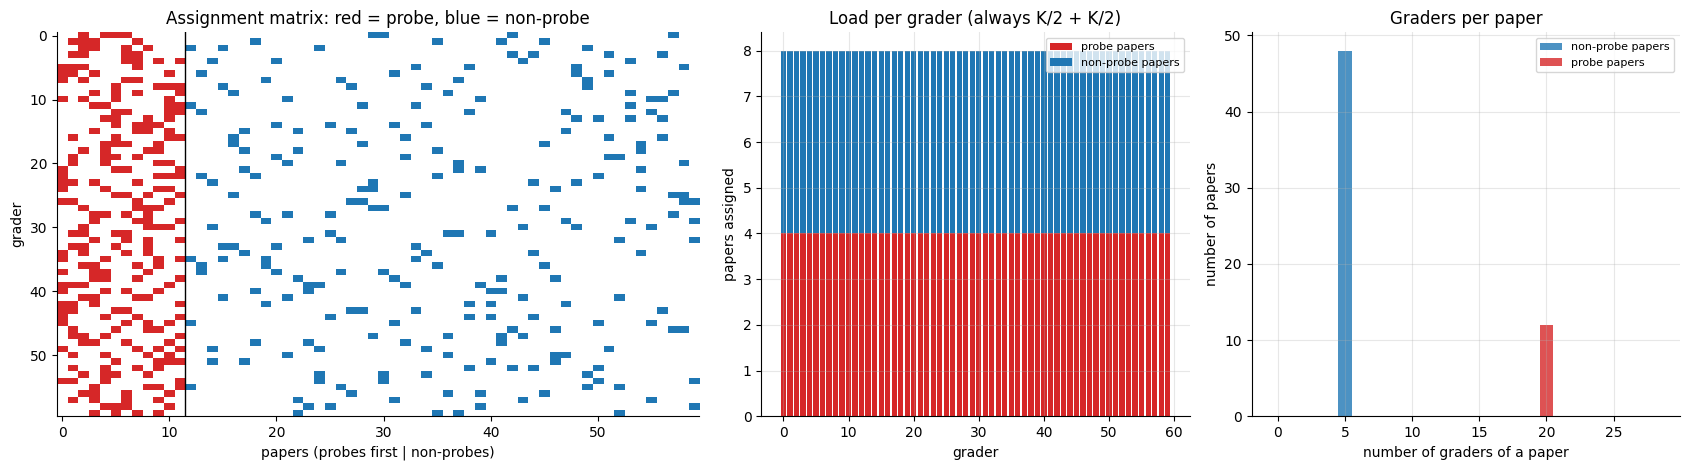

n=60, K=8, probes l=12
graders per NON-probe paper: min 5, mean 5.00, max 5
graders per PROBE paper    : min 20, mean 20.00, max 20

Example - grader 1 receives:
   probes     : [12, 34, 45, 50]
   non-probes : [22, 23, 36, 56]
Example - non-probe paper 1 is graded by graders: [3, 12, 36, 46, 56]


In [4]:
# ---------------- (b) full-size round: n=60, K=8, l=12 ----------------------------------------------------------
cfg_demo = SimConfig()
A_d, ip_d = make_assignment(cfg_demo.n, cfg_demo.K, cfg_demo.n_probes, np.random.default_rng(SEED))
order = np.r_[np.where(ip_d)[0], np.where(~ip_d)[0]]            # probe papers first, for readability
n_ = cfg_demo.n

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.5, 1, 1]})
img = np.zeros((n_, n_))
img[A_d[:, order] & ip_d[order][None, :]] = 1               # probe assignment
img[A_d[:, order] & ~ip_d[order][None, :]] = 2              # non-probe assignment
from matplotlib.colors import ListedColormap
axes[0].imshow(img, cmap=ListedColormap(["white", "tab:red", "tab:blue"]), aspect="auto", interpolation="nearest")
axes[0].axvline(ip_d.sum() - 0.5, color="k", lw=1)
axes[0].set_xlabel("papers (probes first | non-probes)"); axes[0].set_ylabel("grader")
axes[0].set_title("Assignment matrix: red = probe, blue = non-probe"); axes[0].grid(False)

pr_load = (A_d & ip_d[None, :]).sum(1); np_load = (A_d & ~ip_d[None, :]).sum(1)
axes[1].bar(np.arange(n_), pr_load, color="tab:red", label="probe papers")
axes[1].bar(np.arange(n_), np_load, bottom=pr_load, color="tab:blue", label="non-probe papers")
axes[1].set_xlabel("grader"); axes[1].set_ylabel("papers assigned"); axes[1].set_title("Load per grader (always K/2 + K/2)")
axes[1].legend(fontsize=8)

axes[2].hist(A_d.sum(0)[~ip_d], bins=np.arange(0, 30) - 0.5, color="tab:blue", alpha=.8, label="non-probe papers")
axes[2].hist(A_d.sum(0)[ip_d], bins=np.arange(0, 30) - 0.5, color="tab:red", alpha=.8, label="probe papers")
axes[2].set_xlabel("number of graders of a paper"); axes[2].set_ylabel("number of papers"); axes[2].set_title("Graders per paper"); axes[2].legend(fontsize=8)
plt.tight_layout(); savefig("part1_assignment_overview")

print(f"n={n_}, K={cfg_demo.K}, probes l={int(ip_d.sum())}")
print(f"graders per NON-probe paper: min {A_d.sum(0)[~ip_d].min()}, mean {A_d.sum(0)[~ip_d].mean():.2f}, max {A_d.sum(0)[~ip_d].max()}")
print(f"graders per PROBE paper    : min {A_d.sum(0)[ip_d].min()}, mean {A_d.sum(0)[ip_d].mean():.2f}, max {A_d.sum(0)[ip_d].max()}")
print("\nExample - grader 1 receives:")
g0 = np.where(A_d[0])[0]
print("   probes     :", [int(j) + 1 for j in g0 if ip_d[j]])
print("   non-probes :", [int(j) + 1 for j in g0 if not ip_d[j]])
j0 = int(np.where(~ip_d)[0][0])
print(f"Example - non-probe paper {j0+1} is graded by graders:", [int(i) + 1 for i in np.where(A_d[:, j0])[0]])
pd.DataFrame(A_d.astype(int)).to_csv(os.path.join(DATA_DIR, "assignment_matrix_demo.csv"), index=False)

## Part 2 — Assignment (score-aggregation) rules

Each rule maps the reports of paper $j$'s graders $G(j)$ to a final score $r_j$. All rules are registered in a dictionary `RULES` so that every experiment can loop over them. Interface: `rule(round) -> vector of n assigned scores`.

### 2.1 Mean

$$r_j^{\text{mean}} = \frac{1}{|G(j)|}\sum_{i\in G(j)} \tilde y^{(i)}_j .$$

* It is the maximum-likelihood estimate if all graders were unbiased with **equal** noise.
* Weakness: **zero breakdown point.** A single grader reporting an arbitrarily large number moves the output arbitrarily far. A grader with a competitive utility $u_i = (\text{own score}) - w\sum_{k\ne i} (\text{score}_k)$ can lower the mean by shading down, so truthful reporting is *not* a best response; the mean is not strategyproof (for such preferences) and has no effort incentive.
* A common bias $\delta$ of all graders shifts the mean by exactly $\delta$.

In [5]:
RULES = {}
def register(name):
    def deco(f):
        RULES[name] = f
        return f
    return deco

@register("Mean")
def rule_mean(rd):
    return np.nanmean(rd.Y, axis=0)

print("registered:", list(RULES))

registered: ['Mean']


### 2.2 Median — the benchmark used in practice (e.g. Coursera)

$$r_j^{\text{med}} = \operatorname{median}\{\tilde y^{(i)}_j : i\in G(j)\}.$$

**Why it is "the" strategyproof benchmark (course Part III — domain restriction & the median voter rule).**
If every agent has *single-peaked* preferences over the outcome (she wants the final score as close as possible to her own peak $p_i$), the median rule (optionally with fixed "phantom" voters) is **dominant-strategy incentive compatible (DSIC)**: reporting a value on the wrong side of the median can only move the outcome away from $p_i$; moving it on the right side leaves the median unchanged. Hence, by the revelation principle, truthful reporting is optimal, and the rule is also **robust**: its breakdown point is 50 % (the median cannot be moved outside the range of the honest reports as long as a majority is honest).

**Where it fails in the peer-grading game of the paper.**
1. A *competitive* grader does **not** have single-peaked preferences about paper $j$'s score: her utility is *decreasing* in others' scores, so her "peak" is the minimum possible grade and shading down is a (weakly) dominant move whenever she is pivotal. Strategyproofness is lost (you will verify this by brute force in Part 7).
2. Nothing in the median pays for **precision**: the grading performance score is identically zero, so a rational grader with a cost of effort chooses minimal effort.
3. It does not correct **systematic bias** (if most graders are generous, the median is generous), and it ignores that some graders are much more precise than others.

In [6]:
@register("Median")
def rule_median(rd):
    return np.nanmedian(rd.Y, axis=0)

### 2.3 Joint least-squares (LS) estimator of grader biases and true scores — no ground truth needed

Without instructor-graded papers one can still *calibrate* graders from overlapping reports. Fit the additive two-way model $\tilde y^{(i)}_j = y_j + b_i + \text{noise}$ by least squares:

$$\min_{\{y_j\},\{b_i\}}\ \sum_{(i,j)\in A} \big(\tilde y^{(i)}_j - y_j - b_i\big)^2 \quad\text{s.t.}\quad \sum_i b_i = 0 .$$

The constraint is needed because $(y_j+\delta,\ b_i-\delta)$ gives the same fit: **only relative biases are identifiable** without ground truth. We solve by alternating (backfitting) updates

$$y_j \leftarrow \operatorname{mean}_{i\in G(j)}\big(\tilde y^{(i)}_j-b_i\big),\qquad b_i\leftarrow \operatorname{mean}_{j\in G^{-1}(i)}\big(\tilde y^{(i)}_j-y_j\big),\ \text{then recentre } b.$$

* Equal weights, so heterogeneous precision is ignored.
* Cancels *idiosyncratic* biases (graders that are harsher/more generous than average) but is **blind to a common shift** (all graders generous) — exactly where the probe-based PEQA estimator has an advantage.

In [7]:
@register("Joint LS")
def rule_joint_ls(rd, iters=200):
    Yz = np.nan_to_num(rd.Y); Af = rd.A.astype(float)
    cj = np.maximum(Af.sum(0), 1); ci = np.maximum(Af.sum(1), 1)
    b = np.zeros(rd.cfg.n)
    for _ in range(iters):
        yh = ((Yz - b[:, None]) * Af).sum(0) / cj
        b = ((Yz - yh[None, :]) * Af).sum(1) / ci
        b = b - b.mean()                       # identifiability constraint
    return ((Yz - b[:, None]) * Af).sum(0) / cj

### 2.4 Joint maximum-likelihood / MAP estimator (PG$_1$, Piech et al. 2013)

Add precision and priors:
$b_i\sim\mathcal N(0,1/\eta_0)$, $\tau_i\sim\text{Gamma}(\alpha_0,\beta_0)$, $y_j\sim\mathcal N(\mu,1/\gamma)$ and
$\tilde y^{(i)}_j\sim\mathcal N(y_j+b_i,1/\tau_i)$.
The MAP estimate is obtained by coordinate ascent:

$$y_j=\frac{\gamma\mu+\sum_{i\in G(j)}\tau_i(\tilde y^{(i)}_j-b_i)}{\gamma+\sum_{i\in G(j)}\tau_i},\quad
b_i=\frac{\tau_i\sum_{j}(\tilde y^{(i)}_j-y_j)}{\eta_0+n_i\tau_i},\quad
\tau_i=\frac{\alpha_0-1+n_i/2}{\beta_0+\tfrac12\sum_j(\tilde y^{(i)}_j-y_j-b_i)^2}.$$

This is the *statistician's* answer (precision-weighted, bias-corrected, shrinks to the prior), but it is a pure estimator: it has **no incentive properties**, and, because graders are calibrated against each other (not against ground truth), a coalition or a common shift cannot be detected. It will serve as the "best non-incentive estimator" benchmark.

In [8]:
@register("Joint ML (PG1)")
def rule_joint_ml(rd, iters=100, eta0=1.0, a0=2.0, b0=1.0):
    cfg = rd.cfg
    Yz = np.nan_to_num(rd.Y); Af = rd.A.astype(float)
    ni = Af.sum(1)
    b = np.zeros(cfg.n); tau = np.ones(cfg.n)
    for _ in range(iters):
        num = cfg.gamma * cfg.mu + (tau[:, None] * (Yz - b[:, None]) * Af).sum(0)
        den = cfg.gamma + (tau[:, None] * Af).sum(0)
        yh = num / den
        res = (Yz - yh[None, :]) * Af
        b = tau * res.sum(1) / (eta0 + ni * tau)
        ss = (((Yz - yh[None, :] - b[:, None]) * Af) ** 2).sum(1)
        tau = np.clip((a0 - 1 + ni / 2) / (b0 + 0.5 * ss), 1e-2, 1e3)
    num = cfg.gamma * cfg.mu + (tau[:, None] * (Yz - b[:, None]) * Af).sum(0)
    den = cfg.gamma + (tau[:, None] * Af).sum(0)
    return num / den

### 2.5 PEQA — Peer Evaluation with Quality Assurance (the paper's mechanism)

**Idea.** Use the $\ell$ **probe papers** (graded by the teaching staff) to *measure* every grader, then de-bias and precision-weight her reports. Because probes are indistinguishable from non-probes, the bias/precision measured on probes is the same as on non-probes (the paper's Hypothesis 4, supported by their experiment).

**Estimation (Sec. 2.3).** For grader $i$ with probe set $P_i$ ($|P_i|=K/2\ge2$):

$$\hat b_i=\frac1{|P_i|}\sum_{j\in P_i}(\tilde y^{(i)}_j-y_j),\qquad
\hat\tau_i=\frac{|P_i|-1}{\sum_{j\in P_i}\big(\tilde y^{(i)}_j-(y_j+\hat b_i)\big)^2}.$$

**Score-assignment rule — ISWDM (inverse-standard-deviation-weighted de-biased mean), Eq. (1):**

$$\boxed{\,r_j^{*}=\frac{\sqrt{\gamma}\,\mu+\sum_{i\in G(j)}\sqrt{\hat\tau_i}\,\big(\tilde y^{(i)}_j-\hat b_i\big)}{\sqrt{\gamma}+\sum_{i\in G(j)}\sqrt{\hat\tau_i}}\,}\qquad (r^*_j=y_j\text{ on probes}).$$

* **De-biasing** $\Rightarrow$ the assigned score does not depend on the bias a grader chooses (**EPBI**, ex-post bias insensitivity; Theorem 1). Adding $x$ to all of a grader's reports raises $\hat b_i$ by exactly $x$, which cancels.
* **Weight $\sqrt{\hat\tau_i}=1/\hat\sigma_i$** (not $\hat\tau_i=1/\hat\sigma_i^2$!). The statistically optimal weight for squared error is $\hat\tau_i$ (the *ERM* rule, Eq. 3/26), but **Theorem 2** shows that among weighted-average rules, only weights $\propto 1/\sigma_i$ make a grader's utility monotone in her precision when students can request regrades. So PEQA gives up a little accuracy (Appendix C of the paper: roughly 20 % of the reward in the worst case, vanishing with reliability) in exchange for incentives. We also register the ERM-weight variant **"PEQA-ERM weights"** (power 1) for comparison.

**Grading performance score (VCG-like, Sec. 4, Step 7).** With social reward $W_j=R(r_j^*,y_j)$ (e.g. $R(x,y)=-(x-y)^2$) grader $i$ is paid her *marginal contribution to accuracy* on each non-probe paper she graded:

$$t_i=\alpha\sum_{j\in NP_i}\big(W_j-W_j^{(-i)}\big),$$

where $W_j^{(-i)}$ is the reward if the paper were scored without $i$'s report (other graders' estimated $\hat b,\hat\tau$ unchanged). Theorem 1 ($\sum_k w_{ik}\le1$): in PEQA, a grader's utility is **independent of her bias** (EPBI) and **increasing in her reliability** (EPRM), *whatever she cares about the others and whatever they do* — and the same holds for every weight $\alpha>0$. Part 5 implements $t_i$ and tests this numerically.

In [9]:
def peqa_estimates(Y, A, is_probe, y, cfg):
    """Probe-based estimates (b_hat_i, tau_hat_i) for every grader."""
    Pm = A & is_probe[None, :]
    err = np.where(Pm, Y - y[None, :], np.nan)
    m = Pm.sum(1)
    bhat = np.nansum(err, 1) / m
    ss = np.nansum((err - bhat[:, None]) ** 2, 1)
    tauhat = np.clip((m - 1) / np.maximum(ss, 1e-12), cfg.tau_floor, cfg.tau_cap)
    return bhat, tauhat

def peqa_assign(Y, A, is_probe, y, cfg, power=0.5, est=None):
    """Weighted de-biased mean with weights tau_hat**power.
       power=0.5 -> ISWDM (PEQA);  power=1 -> ERM / statistically optimal weights.
       Returns r (probes get instructor score) and the pieces needed for leave-one-out."""
    bhat, tauhat = est if est is not None else peqa_estimates(Y, A, is_probe, y, cfg)
    s = tauhat ** power
    Yz = np.nan_to_num(Y)
    Wm = np.where(A, s[:, None], 0.0)                         # weight matrix  (grader, paper)
    C = np.where(A, s[:, None] * (Yz - bhat[:, None]), 0.0)   # weighted de-biased reports
    pw = cfg.gamma ** power
    num = pw * cfg.mu + C.sum(0)
    den = pw + Wm.sum(0)
    r = np.where(is_probe, y, num / den)
    return r, num, den, C, Wm, bhat, tauhat

@register("PEQA (ISWDM)")
def rule_peqa(rd):
    return peqa_assign(rd.Y, rd.A, rd.is_probe, rd.y, rd.cfg, power=0.5)[0]

@register("PEQA-ERM weights")
def rule_peqa_erm(rd):
    return peqa_assign(rd.Y, rd.A, rd.is_probe, rd.y, rd.cfg, power=1.0)[0]

# ---------------------------------------------------------------- evaluation helpers
def evaluate_round(rd, names=None):
    out = {}
    for name in (names or RULES):
        r = RULES[name](rd)
        e = (r - rd.y)[rd.np_mask]                              # non-probe papers only
        out[name] = dict(rmse=float(np.sqrt(np.mean(e ** 2))), mae=float(np.mean(np.abs(e))), me=float(np.mean(e)))
    return out

# ---------------------------------------------------------------- unit tests
rng = np.random.default_rng(SEED)
rd = generate_round(SimConfig(), rng)
tab = pd.DataFrame(evaluate_round(rd)).T
print("One round, default configuration:"); display(tab.round(3))

# test 1: PEQA is invariant to a grader's bias (EPBI): shift all of grader 0's reports by +2
rd2 = Round(rd.cfg, rd.y, rd.A, rd.is_probe, rd.Y.copy())
rd2.Y[0] = rd2.Y[0] + 2.0
d = np.abs(RULES["PEQA (ISWDM)"](rd) - RULES["PEQA (ISWDM)"](rd2)).max()
d_mean = np.abs(RULES["Mean"](rd) - RULES["Mean"](rd2)).max()
print(f"EPBI unit test | max change of PEQA scores = {d:.2e}  (mean rule changes by {d_mean:.3f})")
assert d < 1e-9

One round, default configuration:


,rmse,mae,me
Mean,0.344,0.268,-0.039
Median,0.452,0.370,-0.037
Joint LS,0.308,0.248,-0.039
Joint ML (PG1),0.274,0.223,-0.027
PEQA (ISWDM),0.282,0.228,-0.033
PEQA-ERM weights,0.352,0.279,-0.011


EPBI unit test | max change of PEQA scores = 0.00e+00  (mean rule changes by 0.400)


## Part 3 — Experiment A: recovery error as bias and noise increase

Protocol: for each value of the swept parameter we simulate `REPS_SWEEP` independent rounds ($n=60$, $K=8$, $\ell=12$) and report the **RMSE on non-probe papers** (mean ± standard error over rounds).

* **A1** — idiosyncratic bias magnitude $s_b$ grows (graders are individually harsh/generous).
* **A2** — noise level $\sigma$ grows.
* **A3** — *systematic* bias $\delta$ (every grader is generous by $\delta$). This is the case where ground-truth probes matter: rules calibrated only against each other cannot see it.

What theory predicts: Mean/Median degrade with bias (linearly in $s_b$); Joint LS/ML remove *relative* biases; PEQA removes *absolute* bias (including A3) at the price of the noisy $\hat b_i$; under pure noise A2 the precision-weighted rules (ML, PEQA-ERM, PEQA) beat Mean/Median.

[17:23:37] Experiment A finished in 24.2s
[saved] ./peer_grading_outputs/data/expA1_bias_sd.csv
[saved] ./peer_grading_outputs/data/expA2_noise_sd.csv
[saved] ./peer_grading_outputs/data/expA3_bias_shift.csv
[saved] ./peer_grading_outputs/plots/expA_recovery_error.png


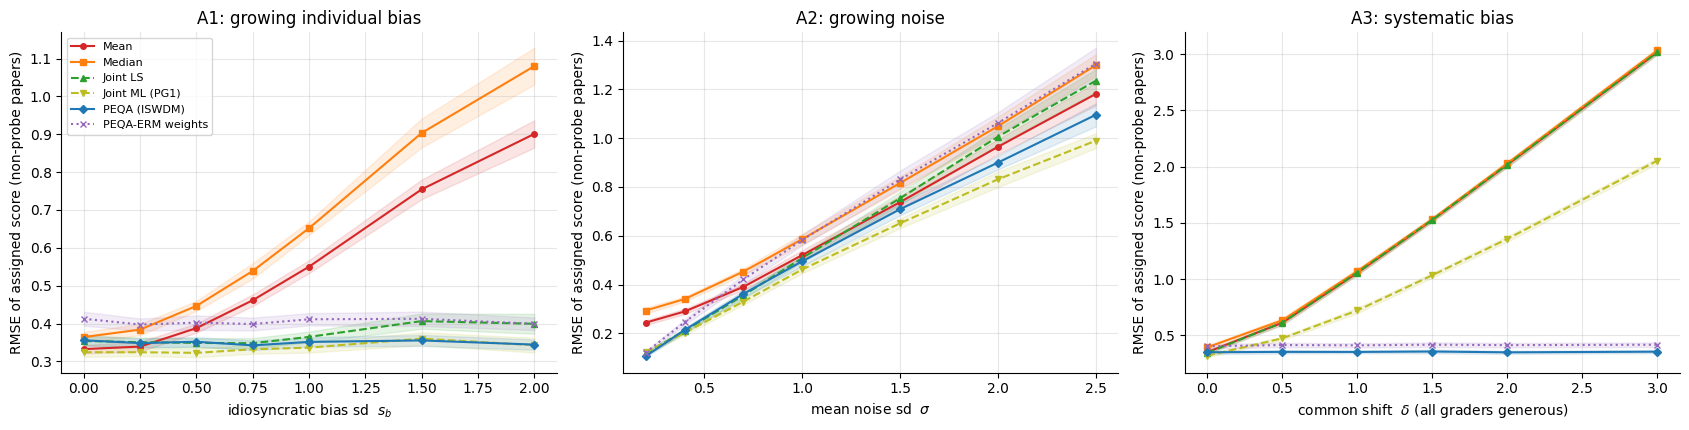

A1 (s_b = 2.0)


rule,Joint LS,Joint ML (PG1),Mean,Median,PEQA (ISWDM),PEQA-ERM weights
mean,0.399,0.343,0.901,1.080,0.344,0.399
sem,0.013,0.010,0.018,0.025,0.007,0.008


A2 (sigma = 2.5)


rule,Joint LS,Joint ML (PG1),Mean,Median,PEQA (ISWDM),PEQA-ERM weights
mean,1.235,0.990,1.181,1.299,1.096,1.305
sem,0.024,0.016,0.024,0.023,0.024,0.033


A3 (delta = 3.0)


rule,Joint LS,Joint ML (PG1),Mean,Median,PEQA (ISWDM),PEQA-ERM weights
mean,3.018,2.053,3.018,3.034,0.354,0.416
sem,0.010,0.013,0.010,0.011,0.007,0.010


In [10]:
def run_sweep(param, values, base_cfg, reps, seed, names=None):
    rng = np.random.default_rng(seed)
    rows = []
    for v in values:
        cfg = replace(base_cfg, **{param: v})
        for rep in range(reps):
            rd = generate_round(cfg, rng)
            for name, m in evaluate_round(rd, names).items():
                rows.append(dict(param=param, value=v, rep=rep, rule=name, **m))
    return pd.DataFrame(rows)

def summarize(df):
    g = df.groupby(["value", "rule"])["rmse"]
    s = g.agg(["mean", "std", "count"]).reset_index()
    s["sem"] = s["std"] / np.sqrt(s["count"])
    return s

STYLE = {"Mean": ("tab:red", "o", "-"), "Median": ("tab:orange", "s", "-"),
         "Joint LS": ("tab:green", "^", "--"), "Joint ML (PG1)": ("tab:olive", "v", "--"),
         "PEQA (ISWDM)": ("tab:blue", "D", "-"), "PEQA-ERM weights": ("tab:purple", "x", ":")}

def plot_sweep(ax, s, xlabel, title, ylabel="RMSE of assigned score (non-probe papers)"):
    for name in RULES:
        d = s[s.rule == name]
        c, mk, ls = STYLE[name]
        ax.plot(d.value, d["mean"], marker=mk, color=c, ls=ls, label=name, ms=4)
        ax.fill_between(d.value, d["mean"] - 1.96 * d["sem"], d["mean"] + 1.96 * d["sem"], color=c, alpha=0.12)
    ax.set_xlabel(xlabel); ax.set_title(title); ax.set_ylabel(ylabel)

base = SimConfig()
t0 = time.time()
dfA1 = run_sweep("bias_sd", [0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0], replace(base, noise_sd=0.7), REPS_SWEEP, SEED + 1)
dfA2 = run_sweep("noise_sd", [0.2, 0.4, 0.7, 1.0, 1.5, 2.0, 2.5], replace(base, bias_sd=0.5), REPS_SWEEP, SEED + 2)
dfA3 = run_sweep("bias_shift", [0, 0.5, 1.0, 1.5, 2.0, 3.0], replace(base, bias_sd=0.3), REPS_SWEEP, SEED + 3)
log(f"Experiment A finished in {time.time()-t0:.1f}s")
for nm, d in (("expA1_bias_sd", dfA1), ("expA2_noise_sd", dfA2), ("expA3_bias_shift", dfA3)):
    save_df(d, nm)

sA1, sA2, sA3 = summarize(dfA1), summarize(dfA2), summarize(dfA3)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
plot_sweep(axes[0], sA1, "idiosyncratic bias sd  $s_b$", "A1: growing individual bias")
plot_sweep(axes[1], sA2, "mean noise sd  $\\sigma$", "A2: growing noise")
plot_sweep(axes[2], sA3, "common shift  $\\delta$ (all graders generous)", "A3: systematic bias")
axes[0].legend(fontsize=8)
plt.tight_layout(); savefig("expA_recovery_error")

for nm, s in (("A1 (s_b = 2.0)", sA1[sA1.value == 2.0]), ("A2 (sigma = 2.5)", sA2[sA2.value == 2.5]), ("A3 (delta = 3.0)", sA3[sA3.value == 3.0])):
    print(nm); display(s[["rule", "mean", "sem"]].set_index("rule").round(3).T)

**Reading the plots:**
* **A1:** the error of Mean/Median grows almost linearly with $s_b$; every rule that estimates grader biases stays nearly flat. PEQA estimates $b_i$ from only $K/2=4$ probe observations, so its bias estimate has noise $\approx\sigma_i/\sqrt 4$. Even so, PEQA matches the MAP estimator here and beats plain LS (which ignores differences in precision); the all-reports estimators have an edge only when noise is low.
* **A2:** with growing noise, precision weighting helps only modestly here (graders' noise levels differ by at most a factor 3). The MAP estimator is best because it pools all $K$ reports of a grader and shrinks to the prior. The probe-based weights use only $K/2-1=3$ degrees of freedom, so $\hat\tau_i$ is itself noisy; the more aggressive $\hat\tau$ weights (PEQA-ERM) then *amplify* that noise, and PEQA's milder $\sqrt{\hat\tau}$ weights are the safer compromise — a small practical point in favour of ISWDM on top of its incentive properties.
* **A3:** a common shift moves Mean, Median and Joint LS one-for-one (they cannot identify it), the MAP estimator only partly (its prior $b_i\sim\mathcal N(0,\cdot)$ is violated), while **PEQA is unaffected because the probes anchor the absolute scale**.

## Part 4 — Experiment B: adversarial graders (median robust, mean not)

A fraction $f$ of the graders is adversarial. Three behaviours:

* **shift**: always report $y_j-5$ (a harsh "grade aggressively" attack, a bias of $-5$);
* **zero**: always report $0$ (an outlier / pure sabotage report, independent of the paper);
* **random** (B3): report a uniform random number on $[0,10]$, independent of the paper (a grader who does not read the paper, or pure noise injection).

Prediction from §2.1–2.2: the **mean is moved linearly** by $f\times$(attack size); the **median ignores a minority** (breakdown at $f\approx50\%$ of the graders *of that paper*, and since papers only have about 5–6 graders and adversaries are random, errors already appear at moderate $f$); PEQA de-biases "shift" adversaries (their $\hat b_i\approx-5$ is subtracted) and gives "zero" and "random" adversaries a tiny weight (their probe residuals are huge, so $\hat\tau_i$ is small). Unlike "zero", the "random" attack is unbiased on average (mean report 5 vs. true mean 6, i.e. a small bias) but extremely noisy, so it tests *precision weighting* rather than robustness to a one-sided push.

[17:24:00] Experiment B finished in 20.7s
[saved] ./peer_grading_outputs/data/expB1_adversary_shift.csv
[saved] ./peer_grading_outputs/data/expB2_adversary_zero.csv
[saved] ./peer_grading_outputs/data/expB3_adversary_random.csv
[saved] ./peer_grading_outputs/plots/expB_adversaries.png


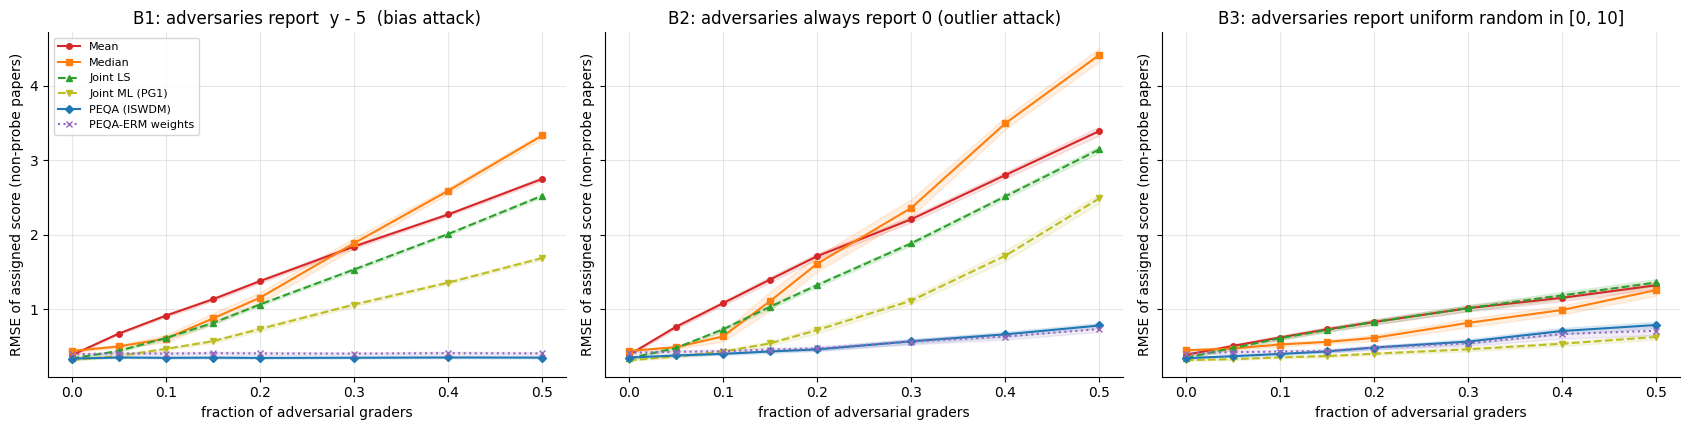


=== Verification: median is robust to a FEW adversaries, the mean is not ===


,attack,frac,mean_rmse,median_rmse,mean_blowup,median_blowup
0,B1 shift,0.05,0.676,0.504,1.748,1.136
1,B1 shift,0.10,0.917,0.608,2.370,1.370
2,B2 zero,0.05,0.766,0.494,1.966,1.111
3,B2 zero,0.10,1.082,0.638,2.779,1.435
4,B3 random,0.05,0.512,0.476,1.307,1.050
5,B3 random,0.10,0.624,0.530,1.593,1.169


[saved] ./peer_grading_outputs/data/expB_verification_table.csv
B1 shift  f=0.05: error x1.75 for Mean vs x1.14 for Median  -> median more robust
B1 shift  f=0.10: error x2.37 for Mean vs x1.37 for Median  -> median more robust
B2 zero   f=0.05: error x1.97 for Mean vs x1.11 for Median  -> median more robust
B2 zero   f=0.10: error x2.78 for Mean vs x1.43 for Median  -> median more robust
B3 random f=0.05: error x1.31 for Mean vs x1.05 for Median  -> median more robust
B3 random f=0.10: error x1.59 for Mean vs x1.17 for Median  -> median more robust


In [11]:
fr_vals = [0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]
t0 = time.time()
dfB1 = run_sweep("adv_frac", fr_vals, replace(base, adv_type="shift", adv_shift=-5.0), REPS_SWEEP, SEED + 4)
dfB2 = run_sweep("adv_frac", fr_vals, replace(base, adv_type="zero"), REPS_SWEEP, SEED + 5)
dfB3 = run_sweep("adv_frac", fr_vals, replace(base, adv_type="random"), REPS_SWEEP, SEED + 6)
log(f"Experiment B finished in {time.time()-t0:.1f}s")
save_df(dfB1, "expB1_adversary_shift"); save_df(dfB2, "expB2_adversary_zero"); save_df(dfB3, "expB3_adversary_random")
sB1, sB2, sB3 = summarize(dfB1), summarize(dfB2), summarize(dfB3)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), sharey=True)
plot_sweep(axes[0], sB1, "fraction of adversarial graders", "B1: adversaries report  y - 5  (bias attack)")
plot_sweep(axes[1], sB2, "fraction of adversarial graders", "B2: adversaries always report 0 (outlier attack)")
plot_sweep(axes[2], sB3, "fraction of adversarial graders", "B3: adversaries report uniform random in [0, 10]")
axes[0].legend(fontsize=8)
plt.tight_layout(); savefig("expB_adversaries")

# ---- the explicit verification asked for in the project text
print("\n=== Verification: median is robust to a FEW adversaries, the mean is not ===")
rows = []
for lab, s in (("B1 shift", sB1), ("B2 zero", sB2), ("B3 random", sB3)):
    base_err = s[(s.value == 0)].set_index("rule")["mean"]
    for f in (0.05, 0.1):
        e = s[(s.value == f)].set_index("rule")["mean"]
        rows.append(dict(attack=lab, frac=f,
                         mean_rmse=e["Mean"], median_rmse=e["Median"],
                         mean_blowup=e["Mean"] / base_err["Mean"], median_blowup=e["Median"] / base_err["Median"]))
ver = pd.DataFrame(rows)
display(ver.round(3)); save_df(ver, "expB_verification_table")
for _, r in ver.iterrows():
    ok = r.mean_blowup > r.median_blowup
    print(f"{r.attack:9s} f={r.frac:.2f}: error x{r.mean_blowup:.2f} for Mean vs x{r.median_blowup:.2f} for Median  -> "
          f"{'median more robust' if ok else 'UNEXPECTED: median not more robust'}")

**Reading Experiment B.**
* **B1 (shift) and B2 (zero):** the mean degrades fastest; the median holds up for a small minority and then breaks down as adversaries start to form a majority on individual papers; PEQA stays best because it removes the shift (B1) or down-weights the useless reports (B2).
* **B3 (random):** the attack is much milder for every rule (random reports average 5, close to the true mean of 6, so there is little systematic push) — it is a *noise* attack. The median is still more robust than the mean (error ×1.17 vs ×1.59 at 10 % adversaries). Precision-weighting rules gain the most: the **Joint ML** estimator is best here, since it measures each grader's noise from all $K$ of her reports, while PEQA measures it only from her $K/2$ probes and therefore identifies noisy graders less sharply — yet PEQA still beats Mean, Median and Joint LS at every adversary share.

## Part 5 — Grading performance score, bias/reliability monotonicity, and the effort game

### 5.1 Theory

**Utilities.** Student $i$'s utility in the paper is (Eq. 5)

$$u_i \;=\; g_i + t_i \;-\; \sum_{j\neq i} w_{ij}\,(g_j+t_j) \;-\; \underbrace{K\,c_i(\tau_i)}_{\text{grading cost}},\qquad w_{ij}\ge 0,$$

with $g_i=\max(r_i,y_i)$ her final exam score after regrading and $t_i$ her grading performance score. The $w_{ij}>0$ terms make her **competitive** (gains when peers score lower). Cost is paid on all $K$ papers because probes and non-probes look identical.

**Performance score = marginal contribution (VCG-style).** $t_i=\alpha\sum_{j\in NP_i}(W_j-W^{(-i)}_j)$ where $W_j=R(r_j,y_j)=-(r_j-y_j)^2$ (with regrading: the "true" score is $y_j$ if a regrade is requested, i.e. $r_j<y_j$, else $r_j$ itself). Because $W^{(-i)}_j$ does not depend on $i$'s own report, $i$'s payoff from paper $j$ is $\alpha W_j$ + (term independent of her actions): she internalises the accuracy of the final score — like the Groves/VCG logic of course Part IV.

**Theorem 1 (EPBI + EPRM).** If $\sum_k w_{ik}\le1$: (i) $i$'s expected utility is *independent of her bias* $b_i$; (ii) it is *increasing in her reliability* $\tau_i$, for every behaviour of the co-graders. (Section 5.3 verifies this numerically.)

**Costly effort and efficiency (Section 6 of the paper).** The planner's social utility for non-probe paper $j$ is $\beta R(r_j,y_j)-\sum_{i\in G(j)}c(\tau_i)$. Because grader $i$ only gets paid when the paper is a non-probe (probability $p_{NP}=1/2$ here), choose

$$\alpha=\beta/p_{NP}.$$

Then grader $i$'s relevant payoff $\beta\bar R(\tau_i,\tau_{-i})-c(\tau_i)$ coincides, as a function of her own effort, with the social utility: the effort game is an **exact potential game** whose potential is the social utility, so **every maximiser of the social utility is a pure Nash equilibrium** (Theorem 3). In the simulation:

* $\mathrm{BR}_i(\tau_{-i})=\arg\max_{\tau}\ \alpha\,\mathbb E\!\big[\textstyle\sum_{j\in NP_i}(W_j-W_j^{(-i)})\big]-K c_i(\tau)$ is computed numerically (common random numbers → smooth objective);
* the equilibrium is found by iterating best responses; the social optimum is found by maximising the social utility $S(\boldsymbol\tau)=\alpha\sum_{j\in NP}W_j-K\sum_i c_i(\tau_i)$ directly; we compare the two.

**Modified PEQA (Eq. 10–12).** Competitive terms are cancelled by paying $\pi_i=t_i+w\sum_{j\ne i}(g_j+\pi_j)$ (uniform $w$). Then $u_i=g_i+t_i-Kc(\tau_i)$ (Eq. 13), which is what the effort game above uses. **Lemma 1:** ranking by $g_i+\pi_i$ equals ranking by $g_i+t_i$ (checked numerically below).

**Regrading caveat (what we will observe).** With regrades, the *mechanism's* reward is one-sided ($W_j=-\max(y_j-r_j,0)^2$) while a planner who cares about true squared error uses $-(r_j-y_j)^2$. The potential-game argument then makes the equilibrium maximise the *mechanism's* objective, which is close to — but not identical to — the planner's. We report both.

In [12]:
# =====================================================================================
#  Performance score implementation (vectorised leave-one-out)
# =====================================================================================
def peqa_outcome(Y, A, is_probe, y, cfg, alpha=1.0, regrade=True, power=0.5):
    """Full PEQA outcome: assigned score r, final score g (after regrading), performance score t, reward W."""
    r, num, den, C, Wm, bhat, tauhat = peqa_assign(Y, A, is_probe, y, cfg, power)
    r_loo = (num[None, :] - C) / (den[None, :] - Wm)            # score of paper j WITHOUT grader i  (i x j)
    y_eff = np.where(r < y, y, r) if regrade else y             # "true score" the mechanism believes
    W     = -(r - y_eff) ** 2                                   # reward with grader i
    W_loo = -(r_loo - y_eff[None, :]) ** 2                      # reward without grader i
    contrib = np.where(A & ~is_probe[None, :], W[None, :] - W_loo, 0.0)   # only non-probe papers pay
    t = alpha * contrib.sum(1)
    g = np.maximum(r, y) if regrade else r
    return dict(r=r, g=g, t=t, W=W, bhat=bhat, tauhat=tauhat)

def simple_outcome(kind, Y, y, regrade=True):
    """Mean / Median: no performance score (t = 0), same regrading rule."""
    r = np.nanmedian(Y, 0) if kind == "Median" else np.nanmean(Y, 0)
    g = np.maximum(r, y) if regrade else r
    return dict(r=r, g=g, t=np.zeros_like(r))

def mech_outcome(mech, Y, A, is_probe, y, cfg, alpha=1.0, regrade=True):
    if mech == "PEQA":
        return peqa_outcome(Y, A, is_probe, y, cfg, alpha, regrade)
    return simple_outcome(mech, Y, y, regrade)

# ---- environments with common random numbers: (true scores, assignment, noise draws z) --------
GCFG  = SimConfig(n=40, K=8, n_probes=8)         # game configuration  (K/2+1=5 <= 8 <= 40/5=8)
ALPHA = 10.0                                     # performance-score weight  alpha = beta / p_NP
KAPPA = 0.01                                     # cost c(tau) = kappa * tau^2 / 2  per paper

def make_envs(cfg, reps, rng):
    envs = []
    for _ in range(reps):
        y = rng.normal(cfg.mu, cfg.sd_true, cfg.n)
        A, ip = make_assignment(cfg.n, cfg.K, cfg.n_probes, rng)
        envs.append(dict(y=y, A=A, ip=ip, z=rng.standard_normal((cfg.n, cfg.n))))
    return envs

def effort_cost(tau, kappa, cfg=GCFG):
    return cfg.K * kappa * np.asarray(tau) ** 2 / 2.0

def focal_t_curve(envs, focal, tau_grid, tau_others, cfg, alpha, regrade=True, focal_bias=0.0, power=0.5):
    """Expected performance score of grader `focal` for each effort in tau_grid (others fixed at tau_others,
    unbiased). Fast path: the others' contribution is computed once, only the focal grader's terms vary."""
    tau_grid = np.asarray(tau_grid, float)
    tot = np.zeros(len(tau_grid)); pw = cfg.gamma ** power
    for e in envs:
        y, A, ip, z = e["y"], e["A"], e["ip"], e["z"]
        Yo = build_reports(y, A, np.zeros(cfg.n), tau_others, z)
        Yo[focal] = np.nan; Ao = A.copy(); Ao[focal] = False
        bh, th = peqa_estimates(Yo, Ao, ip, y, cfg)
        s = th ** power; Yz = np.nan_to_num(Yo)
        Wm = np.where(Ao, s[:, None], 0.0)
        Cm = np.where(Ao, s[:, None] * (Yz - bh[:, None]), 0.0)
        num_o = pw * cfg.mu + Cm.sum(0); den_o = pw + Wm.sum(0)       # score of every paper WITHOUT the focal grader
        pr = np.where(A[focal] & ip)[0]; npj = np.where(A[focal] & ~ip)[0]
        err_p = focal_bias + z[focal, pr][None, :] / np.sqrt(tau_grid)[:, None]
        bf = err_p.mean(1)
        ss = ((err_p - bf[:, None]) ** 2).sum(1)
        thf = np.clip((len(pr) - 1) / np.maximum(ss, 1e-12), cfg.tau_floor, cfg.tau_cap); sf = thf ** power
        d = y[npj][None, :] + focal_bias + z[focal, npj][None, :] / np.sqrt(tau_grid)[:, None] - bf[:, None]
        r  = (num_o[npj][None, :] + sf[:, None] * d) / (den_o[npj][None, :] + sf[:, None])
        rl = (num_o[npj] / den_o[npj])[None, :]
        yn = y[npj][None, :]
        ye = np.where(r < yn, yn, r) if regrade else np.broadcast_to(yn, r.shape)
        tot += alpha * ((-(r - ye) ** 2) - (-(rl - ye) ** 2)).sum(1)
    return tot / len(envs)

# ---- consistency test: fast path == full path ---------------------------------------------
_rng = np.random.default_rng(SEED + 10)
envs = make_envs(GCFG, REPS_ENV, _rng)
_grid = np.array([0.5, 2.0, 8.0]); _tau_o = np.full(GCFG.n, 2.0)
for _rg in (True, False):
    fast = focal_t_curve(envs[:20], 0, _grid, _tau_o, GCFG, ALPHA, regrade=_rg)
    full = np.zeros(len(_grid))
    for e in envs[:20]:
        for k, tg in enumerate(_grid):
            tv = _tau_o.copy(); tv[0] = tg
            Y = build_reports(e["y"], e["A"], np.zeros(GCFG.n), tv, e["z"])
            full[k] += peqa_outcome(Y, e["A"], e["ip"], e["y"], GCFG, ALPHA, _rg)["t"][0]
    full /= 20
    assert np.allclose(fast, full), (fast, full)
print("Fast focal-grader path agrees with the full mechanism computation.")
log(f"Game environments ready: {len(envs)} rounds, n={GCFG.n}, K={GCFG.K}, probes={GCFG.n_probes}")

Fast focal-grader path agrees with the full mechanism computation.
[17:24:01] Game environments ready: 150 rounds, n=40, K=8, probes=8


### 5.2 Modified PEQA and Lemma 1 (order invariance)

We compute $\pi_i$ by solving the linear system $\pi_i=t_i+w\sum_{j\ne i}(g_j+\pi_j)$ directly and compare with the closed form of Eq. (11)–(12); then check that (a) the net utility is $g_i+t_i$ (the competitive component is perfectly compensated), and (b) the ranking by $g_i+\pi_i$ equals that by $g_i+t_i$.

In [13]:
e = envs[0]
Y = build_reports(e["y"], e["A"], np.zeros(GCFG.n), np.full(GCFG.n, 2.0), e["z"])
o = peqa_outcome(Y, e["A"], e["ip"], e["y"], GCFG, ALPHA, regrade=True)
n = GCFG.n; w = 0.5 / (n - 1)                       # uniform other-regarding weight, w != 1/(n-1)
g, t = o["g"], o["t"]

# (a) solve  pi = t + w * ( (G + Pi) 1 - (g + pi) )  as a linear system
M_ = np.eye(n) - w * (np.ones((n, n)) - np.eye(n))
# exact system: pi_i - w*sum_{j!=i} pi_j = t_i + w*sum_{j!=i} g_j
pi_lin = np.linalg.solve(M_, t + w * (g.sum() - g))
# (b) closed form (Eq. 11-12)
Pi = (t.sum() + w * (n - 1) * g.sum()) / (1 - w * (n - 1))
pi_cf = (t + w * (g.sum() - g) + w * Pi) / (1 + w)
print("max |pi_linear - pi_closed_form| =", np.abs(pi_lin - pi_cf).max())
assert np.allclose(pi_lin, pi_cf)

# (c) net utility without cost: g_i + pi_i - w * sum_{j!=i}(g_j + pi_j)  ==  g_i + t_i
u_net = g + pi_lin - w * ((g + pi_lin).sum() - (g + pi_lin))
print("max | net utility - (g+t) | =", np.abs(u_net - (g + t)).max())
assert np.allclose(u_net, g + t)

# (d) Lemma 1: same ranking
same = np.array_equal(np.argsort(-(g + pi_lin), kind="stable"), np.argsort(-(g + t), kind="stable"))
print("Lemma 1 (order invariance) holds:", same)
assert same

max |pi_linear - pi_closed_form| = 5.329070518200751e-15
max | net utility - (g+t) | = 5.329070518200751e-15
Lemma 1 (order invariance) holds: True


### 5.3 Experiment C1 — EPBI and EPRM, numerically

For one focal grader (all others honest, $\tau=2$) we compute the expected performance score $t_i$ as a function of her chosen **bias** $b_i$ (at several effort levels) and of her **reliability** $\tau_i$ (at several biases). Theory (Thm 1): $t_i$ is **flat in $b_i$** and **increasing in $\tau_i$**. For contrast, the "performance score" under Median/Mean is identically zero.

[saved] ./peer_grading_outputs/plots/expC1_EPBI_EPRM.png


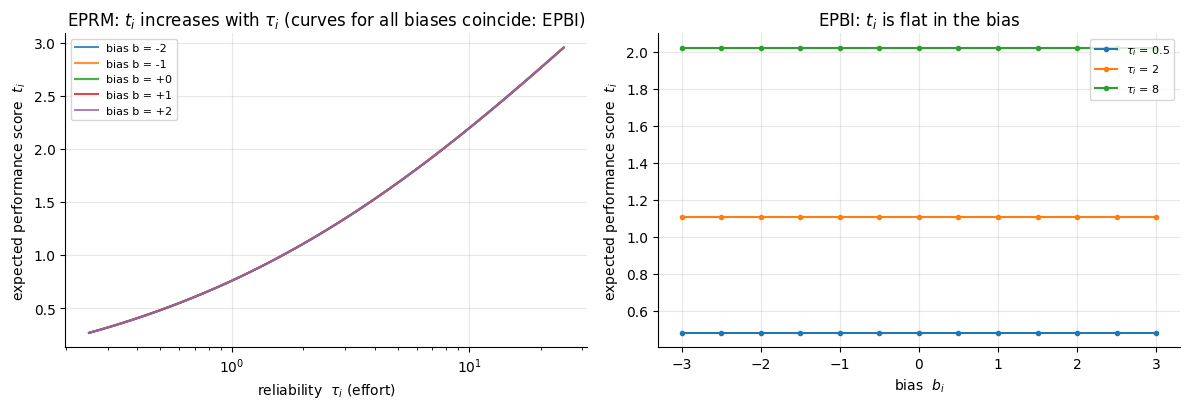

[saved] ./peer_grading_outputs/data/expC1_t_vs_tau_bias.csv
max |t(b=2) - t(b=0)|  (EPBI, should be ~0): 3.11e-15
fraction of effort-grid steps where t increases (EPRM): 1.000


In [14]:
TG = np.exp(np.linspace(np.log(0.25), np.log(25), 100))      # effort grid
biases = [-2, -1, 0, 1, 2]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
rows = []
for b in biases:
    cur = focal_t_curve(envs, 0, TG, np.full(GCFG.n, 2.0), GCFG, ALPHA, regrade=True, focal_bias=b)
    axes[0].plot(TG, cur, label=f"bias b = {b:+d}", lw=1.6 - 0.2 * abs(b) / 2, alpha=.85)
    rows += [dict(bias=b, tau=tt, t=v) for tt, v in zip(TG, cur)]
axes[0].set_xscale("log"); axes[0].set_xlabel("reliability  $\\tau_i$ (effort)"); axes[0].set_ylabel("expected performance score  $t_i$")
axes[0].set_title("EPRM: $t_i$ increases with $\\tau_i$ (curves for all biases coincide: EPBI)"); axes[0].legend(fontsize=8)
for tt in (0.5, 2, 8):
    vals = [focal_t_curve(envs, 0, [tt], np.full(GCFG.n, 2.0), GCFG, ALPHA, True, focal_bias=b)[0] for b in np.linspace(-3, 3, 13)]
    axes[1].plot(np.linspace(-3, 3, 13), vals, marker="o", ms=3, label=f"$\\tau_i$ = {tt}")
axes[1].set_xlabel("bias  $b_i$"); axes[1].set_ylabel("expected performance score  $t_i$")
axes[1].set_title("EPBI: $t_i$ is flat in the bias"); axes[1].legend(fontsize=8)
plt.tight_layout(); savefig("expC1_EPBI_EPRM")
save_df(pd.DataFrame(rows), "expC1_t_vs_tau_bias")

c0 = focal_t_curve(envs, 0, TG, np.full(GCFG.n, 2.0), GCFG, ALPHA, True, focal_bias=0.0)
c2 = focal_t_curve(envs, 0, TG, np.full(GCFG.n, 2.0), GCFG, ALPHA, True, focal_bias=2.0)
print("max |t(b=2) - t(b=0)|  (EPBI, should be ~0): %.2e" % np.abs(c2 - c0).max())
print("fraction of effort-grid steps where t increases (EPRM): %.3f" % np.mean(np.diff(c0) > 0))

### 5.4 Experiment C2 — best-response effort, equilibrium effort profile, and the social optimum

Setup: $n=40$ graders, $K=8$, $\ell=8$ probes, $\alpha=10$, cost $c_i(\tau)=\kappa_i\tau^2/2$ per paper with $\kappa_i=0.01\cdot m_i$.

1. **Symmetric game** ($m_i=1$): best-response curve $\mathrm{BR}(\tau_{\text{others}})$; its fixed point is the symmetric equilibrium. Compare with the social optimum of $S(\boldsymbol\tau)$. For **Mean/Median** there is no performance score, so the best response is the lowest effort.
2. **Heterogeneous costs** (three types, $m_i\in\{0.5,1,2\}$): iterate best responses to an equilibrium *profile* and compare it to the profile that maximises social utility. Done twice: without regrading (exact Theorem 3 setting) and with regrading (Assumption 1).

[17:24:19] Symmetric game solved in 13.2s: {False: {'NE': 3.061219826624409, 'SO_mech': 3.033955693740087}, True: {'NE': 2.4200551952206424, 'SO_mech': 2.3997053393778036, 'SO_true': 3.033955693740087}}
[saved] ./peer_grading_outputs/plots/expC2_best_response_symmetric.png


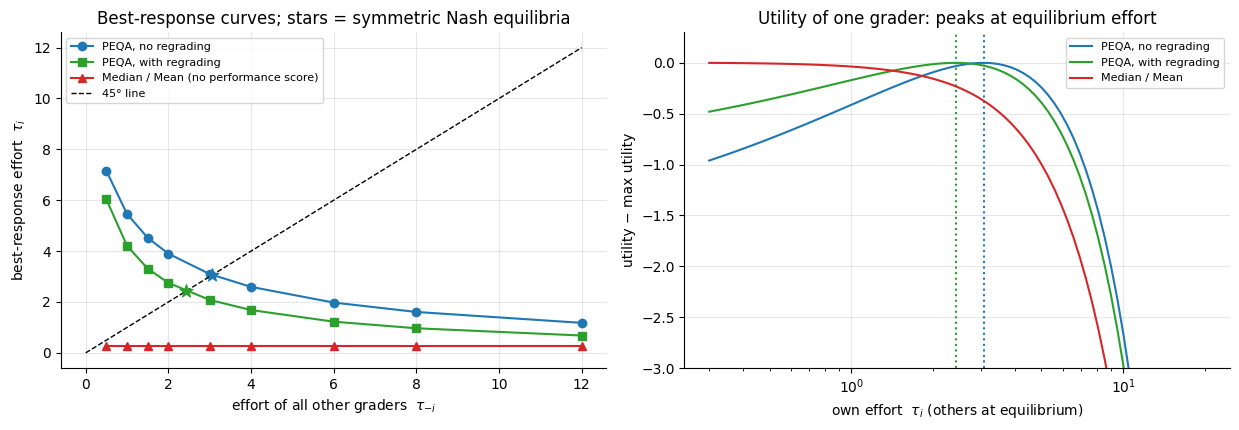

,regrading,NE,SO_mech,SO_true
0,False,3.061,3.034,NaN
1,True,2.420,2.400,3.034


[saved] ./peer_grading_outputs/data/expC2_symmetric_equilibrium_vs_optimum.csv


In [15]:
def best_response(focal, tau_vec, kappa, regrade, envs=envs):
    """Numerical argmax of  E[t_focal](tau) - cost(tau)  given the others' efforts (grid + local refinement)."""
    u = focal_t_curve(envs, focal, TG, tau_vec, GCFG, ALPHA, regrade) - effort_cost(TG, kappa)
    k = int(np.argmax(u)); lo, hi = TG[max(k - 1, 0)], TG[min(k + 1, len(TG) - 1)]
    f = lambda lt: -(focal_t_curve(envs, focal, [np.exp(lt)], tau_vec, GCFG, ALPHA, regrade)[0] - effort_cost(np.exp(lt), kappa))
    res = minimize_scalar(f, bounds=(np.log(lo), np.log(hi)), method="bounded", options=dict(xatol=1e-3))
    return float(np.exp(res.x))

def social_utility(tau_vec, kappa_vec, regrade, planner="mech", envs=envs):
    """S(tau) = alpha * sum_{j in NP} R_j  -  K * sum_i c_i(tau_i).   planner='mech': R = mechanism reward W;
       planner='true': R = -(r-y)^2 (what a planner who cares about true squared error would use)."""
    tot = 0.0
    for e in envs:
        Y = build_reports(e["y"], e["A"], np.zeros(GCFG.n), tau_vec, e["z"])
        o = peqa_outcome(Y, e["A"], e["ip"], e["y"], GCFG, ALPHA, regrade)
        R = o["W"] if planner == "mech" else -(o["r"] - e["y"]) ** 2
        tot += ALPHA * R[~e["ip"]].sum()
    return tot / len(envs) - effort_cost(tau_vec, kappa_vec).sum()

# ---------------------------------------------------------------- (1) symmetric game
t0 = time.time()
tau_oth = np.array([0.5, 1, 1.5, 2, 3, 4, 6, 8, 12])
BR = {rg: [best_response(0, np.full(GCFG.n, to), KAPPA, rg) for to in tau_oth] for rg in (False, True)}

sym = {}
for rg in (False, True):
    f = lambda t: best_response(0, np.full(GCFG.n, t), KAPPA, rg) - t
    ne = brentq(f, 0.5, 16, xtol=1e-3)
    kv = np.full(GCFG.n, KAPPA)
    so = {}
    for planner in (("mech", "true") if rg else ("mech",)):
        r_ = minimize_scalar(lambda lt: -social_utility(np.full(GCFG.n, np.exp(lt)), kv, rg, planner),
                             bounds=(np.log(0.5), np.log(16)), method="bounded", options=dict(xatol=1e-3))
        so[planner] = float(np.exp(r_.x))
    sym[rg] = dict(NE=ne, **{f"SO_{k}": v for k, v in so.items()})
log(f"Symmetric game solved in {time.time()-t0:.1f}s: {sym}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax = axes[0]
ax.plot(tau_oth, BR[False], "o-", color="tab:blue", label="PEQA, no regrading")
ax.plot(tau_oth, BR[True], "s-", color="tab:green", label="PEQA, with regrading")
ax.plot(tau_oth, np.full_like(tau_oth, TG[0]), "^-", color="tab:red", label="Median / Mean (no performance score)")
ax.plot([0, 12], [0, 12], "k--", lw=1, label="45° line")
ax.scatter([sym[False]["NE"]], [sym[False]["NE"]], s=90, marker="*", color="tab:blue", zorder=5)
ax.scatter([sym[True]["NE"]], [sym[True]["NE"]], s=90, marker="*", color="tab:green", zorder=5)
ax.set_xlabel("effort of all other graders  $\\tau_{-i}$"); ax.set_ylabel("best-response effort  $\\tau_i$")
ax.set_title("Best-response curves; stars = symmetric Nash equilibria"); ax.legend(fontsize=8)

ax = axes[1]
tt_ = np.exp(np.linspace(np.log(0.3), np.log(20), 80))
for rg, col in ((False, "tab:blue"), (True, "tab:green")):
    u = focal_t_curve(envs, 0, tt_, np.full(GCFG.n, sym[rg]["NE"]), GCFG, ALPHA, rg) - effort_cost(tt_, KAPPA)
    ax.plot(tt_, u - u.max(), color=col, label=f"PEQA, {'with' if rg else 'no'} regrading")
    ax.axvline(sym[rg]["NE"], color=col, ls=":")
ax.plot(tt_, -effort_cost(tt_, KAPPA) + effort_cost(tt_[0], KAPPA), color="tab:red", label="Median / Mean")
ax.set_xscale("log"); ax.set_ylim(-3, 0.3)
ax.set_xlabel("own effort  $\\tau_i$ (others at equilibrium)"); ax.set_ylabel("utility − max utility")
ax.set_title("Utility of one grader: peaks at equilibrium effort"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("expC2_best_response_symmetric")

symdf = pd.DataFrame([dict(regrading=rg, **v) for rg, v in sym.items()])
display(symdf.round(3)); save_df(symdf, "expC2_symmetric_equilibrium_vs_optimum")

#### What the best response looks like (printed)

The next cell prints, for the **symmetric game**:

1. the best-response table: *if all other graders use effort $\tau_{-i}$, my best effort is …* (PEQA with and without regrading; Mean/Median for contrast);
2. the full utility curve of one grader, split into **expected performance score**, **effort cost** and **net utility**, with the best response marked — so you can see *why* the optimum is where it is (benefit rises with diminishing returns, cost rises quadratically).

Best-response effort of one grader, given that ALL other graders use effort tau_others
(cost c(tau) = K * kappa * tau^2 / 2 with kappa = 0.01 , alpha = 10.0 )

 others_effort_tau  BR_PEQA_no_regrading  BR_PEQA_with_regrading  BR_Median_or_Mean
               0.5                 7.157                   6.033               0.25
               1.0                 5.460                   4.208               0.25
               1.5                 4.523                   3.310               0.25
               2.0                 3.899                   2.752               0.25
               3.0                 3.099                   2.081               0.25
               4.0                 2.593                   1.683               0.25
               6.0                 1.977                   1.226               0.25
               8.0                 1.608                   0.967               0.25
              12.0                 1.179                   0.682               0.25


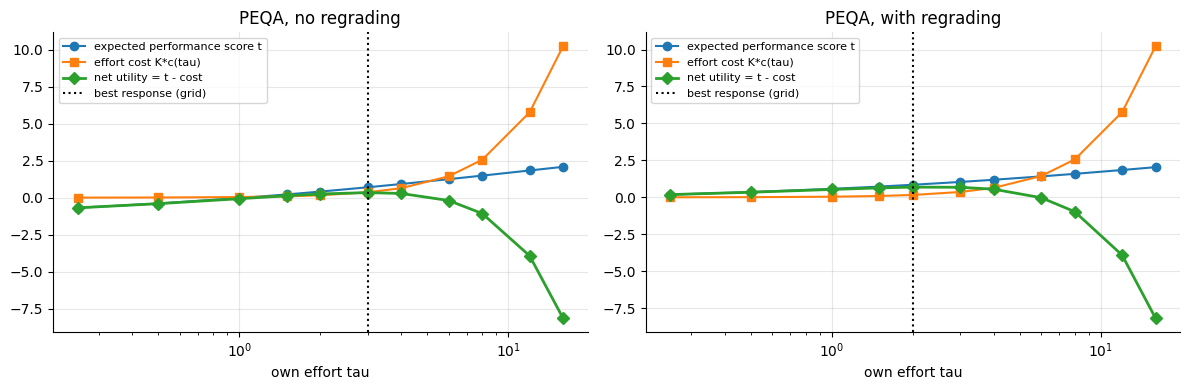

In [16]:
# ---------------- (1) best-response table -----------------------------------------------------------------------
br_table = pd.DataFrame({
    "others_effort_tau": tau_oth,
    "BR_PEQA_no_regrading": np.round(BR[False], 3),
    "BR_PEQA_with_regrading": np.round(BR[True], 3),
    "BR_Median_or_Mean": round(float(TG[0]), 3),
})
print("Best-response effort of one grader, given that ALL other graders use effort tau_others")
print("(cost c(tau) = K * kappa * tau^2 / 2 with kappa =", KAPPA, ", alpha =", ALPHA, ")\n")
print(br_table.to_string(index=False))
print(f"\nSymmetric Nash equilibria (BR(tau)=tau): no regrading tau* = {sym[False]['NE']:.3f}; with regrading tau* = {sym[True]['NE']:.3f}")
print("Median/Mean: best response = lowest allowed effort whatever the others do (no performance score, effort is only a cost).")
save_df(br_table, "expC2_best_response_table")

# ---------------- (2) one grader's utility curve at the equilibrium of the others ------------------------------------
tau_show = np.array([0.25, 0.5, 1, 1.5, 2, 3, 4, 6, 8, 12, 16])
rows = []
for rg in (False, True):
    t_perf = focal_t_curve(envs, 0, tau_show, np.full(GCFG.n, sym[rg]["NE"]), GCFG, ALPHA, rg)
    cost_ = effort_cost(tau_show, KAPPA)
    net = t_perf - cost_
    for tt, a_, c_, n_ in zip(tau_show, t_perf, cost_, net):
        rows.append(dict(regrading=rg, own_tau=tt, expected_performance_score=a_, effort_cost=c_, net_utility=n_, is_best=bool(n_ == net.max())))
curve = pd.DataFrame(rows)
for rg in (False, True):
    print(f"\n--- PEQA {'with' if rg else 'without'} regrading; others at tau = {sym[rg]['NE']:.2f} ---")
    print(curve[curve.regrading == rg].drop(columns="regrading").round(4).to_string(index=False))
    best_row = curve[(curve.regrading == rg) & curve.is_best].iloc[0]
    print(f"=> on this coarse grid the best own effort is {best_row.own_tau} (exact best response: {best_response(0, np.full(GCFG.n, sym[rg]['NE']), KAPPA, rg):.3f})")
save_df(curve, "expC2_utility_curve_at_equilibrium")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, rg in zip(axes, (False, True)):
    d = curve[curve.regrading == rg]
    ax.plot(d.own_tau, d.expected_performance_score, "o-", label="expected performance score t")
    ax.plot(d.own_tau, d.effort_cost, "s-", label="effort cost K*c(tau)")
    ax.plot(d.own_tau, d.net_utility, "D-", lw=2, label="net utility = t - cost")
    b_ = d[d.is_best].iloc[0]; ax.axvline(b_.own_tau, color="k", ls=":", label="best response (grid)")
    ax.set_xscale("log"); ax.set_xlabel("own effort tau"); ax.set_title(f"PEQA, {'with' if rg else 'no'} regrading"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("expC2_best_response_decomposition")

[17:24:50] Heterogeneous game solved in 28.6s


,regrading,planner,NE_type0.5,NE_type1.0,NE_type2.0,SO_type0.5,SO_type1.0,SO_type2.0
0,False,mech,4.444,3.078,2.072,4.380,3.039,2.058
1,True,mech,3.615,2.423,1.609,3.489,2.408,1.599
2,True,true,3.615,2.423,1.609,4.380,3.039,2.058


[saved] ./peer_grading_outputs/data/expC2_heterogeneous_equilibrium_vs_optimum.csv
[saved] ./peer_grading_outputs/plots/expC2_heterogeneous_profile.png


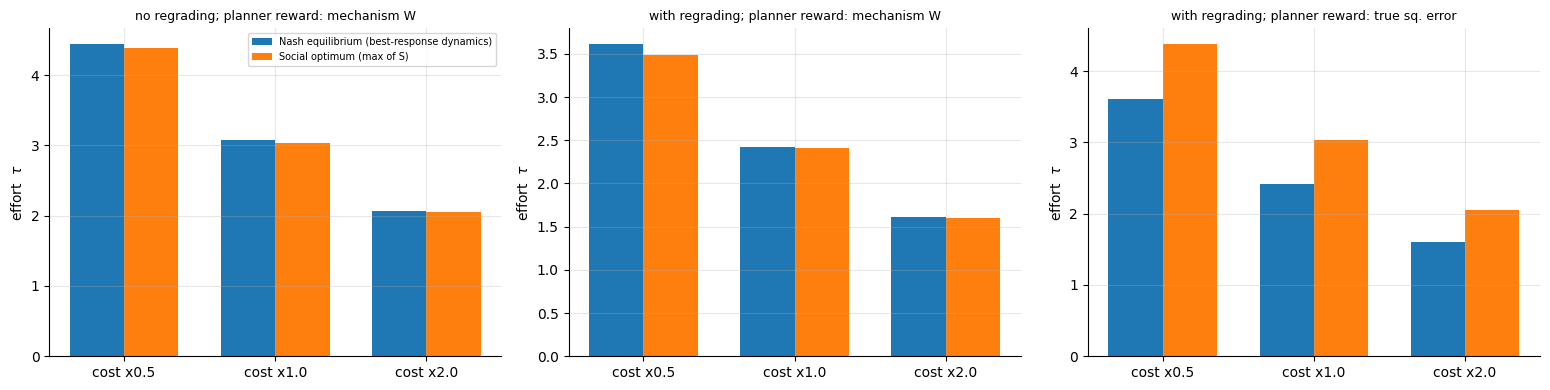

regrading=False planner=mech: max relative gap |NE-SO|/SO = 1.5%
regrading=True  planner=mech: max relative gap |NE-SO|/SO = 3.6%
regrading=True  planner=true: max relative gap |NE-SO|/SO = 21.8%


In [17]:
# ---------------------------------------------------------------- (2) heterogeneous costs
mult = np.array([0.5, 1.0, 2.0])                       # cost multipliers of the 3 grader types
types = np.arange(GCFG.n) % 3
kappa_vec = KAPPA * mult[types]

def profile_to_vec(p):  return np.asarray(p)[types]

def solve_NE(regrade, iters=12, damp=0.6):
    p = np.array([3.0, 3.0, 3.0])
    for it in range(iters):
        new = np.array([best_response(g_, profile_to_vec(p), KAPPA * mult[g_], regrade) for g_ in range(3)])
        p_next = np.exp(damp * np.log(new) + (1 - damp) * np.log(p))       # damped update in log space
        if np.max(np.abs(np.log(p_next / p))) < 2e-3:
            p = p_next; break
        p = p_next
    return p

def solve_SO(regrade, planner):
    f = lambda lp: -social_utility(profile_to_vec(np.exp(lp)), kappa_vec, regrade, planner)
    res = minimize(f, np.log([3.0, 3.0, 3.0]), method="Nelder-Mead", options=dict(xatol=1e-2, fatol=1e-6, maxiter=250))
    return np.exp(res.x)

t0 = time.time()
het = []
for rg in (False, True):
    ne = solve_NE(rg)
    for planner in (("mech",) if not rg else ("mech", "true")):
        so = solve_SO(rg, planner)
        het.append(dict(regrading=rg, planner=planner,
                        **{f"NE_type{m_}": ne[k] for k, m_ in enumerate(mult)},
                        **{f"SO_type{m_}": so[k] for k, m_ in enumerate(mult)}))
log(f"Heterogeneous game solved in {time.time()-t0:.1f}s")
hetdf = pd.DataFrame(het); display(hetdf.round(3)); save_df(hetdf, "expC2_heterogeneous_equilibrium_vs_optimum")

fig, axes = plt.subplots(1, len(het), figsize=(5.2 * len(het), 4))
for ax, row in zip(np.atleast_1d(axes), het):
    x = np.arange(3); wd = 0.36
    ax.bar(x - wd / 2, [row[f"NE_type{m_}"] for m_ in mult], wd, label="Nash equilibrium (best-response dynamics)", color="tab:blue")
    ax.bar(x + wd / 2, [row[f"SO_type{m_}"] for m_ in mult], wd, label="Social optimum (max of S)", color="tab:orange")
    ax.set_xticks(x); ax.set_xticklabels([f"cost x{m_}" for m_ in mult]); ax.set_ylabel("effort  $\\tau$")
    ax.set_title(f"{'with' if row['regrading'] else 'no'} regrading; planner reward: "
                 f"{'mechanism W' if row['planner']=='mech' else 'true sq. error'}", fontsize=9)
np.atleast_1d(axes)[0].legend(fontsize=7)
plt.tight_layout(); savefig("expC2_heterogeneous_profile")

# relative gaps
for row in het:
    ne = np.array([row[f"NE_type{m_}"] for m_ in mult]); so = np.array([row[f"SO_type{m_}"] for m_ in mult])
    print(f"regrading={row['regrading']!s:5} planner={row['planner']:4}: max relative gap |NE-SO|/SO = {np.max(np.abs(ne-so)/so):.1%}")

**Reading Experiment C2.**
* Without regrading (exact Theorem 3 setting) the equilibrium effort profile coincides with the social optimum up to Monte-Carlo / optimiser tolerance (the social-utility surface is very flat near its maximum, so a few-percent gap is optimiser noise; increase `REPS_ENV` to tighten it) — the performance score has aligned private and social incentives. Best responses are *decreasing* in others' effort (graders' efforts are strategic substitutes) but the fixed point is unique and matches the optimum.
* With regrading, the equilibrium still maximises the *mechanism's* reward (the game stays a potential game) but a planner who values true squared error would like **more** effort, because the one-sided reward $-\max(y_j-r_j,0)^2$ is less sensitive to noise than $-(r_j-y_j)^2$. This is a finite-sample, simulation-level caveat of the paper's regrading assumption, not a contradiction of Theorem 3.
* Under Median/Mean the best response is the *minimum* effort, whatever the others do: there is nothing to pay for precision.

## Part 6 — Experiment D: a **competitive** grader

Take one focal grader (index 0) whose utility is $u_0 = g_0+t_0-\sum_{j\ne0}w_j(g_j+t_j)-Kc(\tau_0)$ with $\sum_j w_j=1$ (the maximum allowed by Theorem 1). The other 39 graders are honest, $\tau=2$. She chooses a **bias** $b\in[-2,2]$ (negative = "grade aggressively") and an **effort** $\tau$. We compute her expected net utility by simulation (common random numbers) under

* **Median** and **Mean** (no performance score),
* **PEQA** (original, with performance scores $t$; co-graders' scores $t_k$ enter her utility via $w_k$).

Two rivalry structures: **uniform** ($w_j=1/(n-1)$, the paper's default) and **graded** (all the weight sits on the four non-probe papers she grades — the rivals she can actually influence).

Predictions: under Median/Mean the best response has $b<0$ (shading down is profitable, so truthful reporting is *not* a best response) and minimal effort; under PEQA utility is **flat in $b$** (shading is pointless) and has an interior optimum in $\tau$.

[17:25:06] Experiment D finished in 14.8s
[saved] ./peer_grading_outputs/data/expD_competitive_grader_utilities.csv
[saved] ./peer_grading_outputs/plots/expD_competitive_grader_heatmaps.png


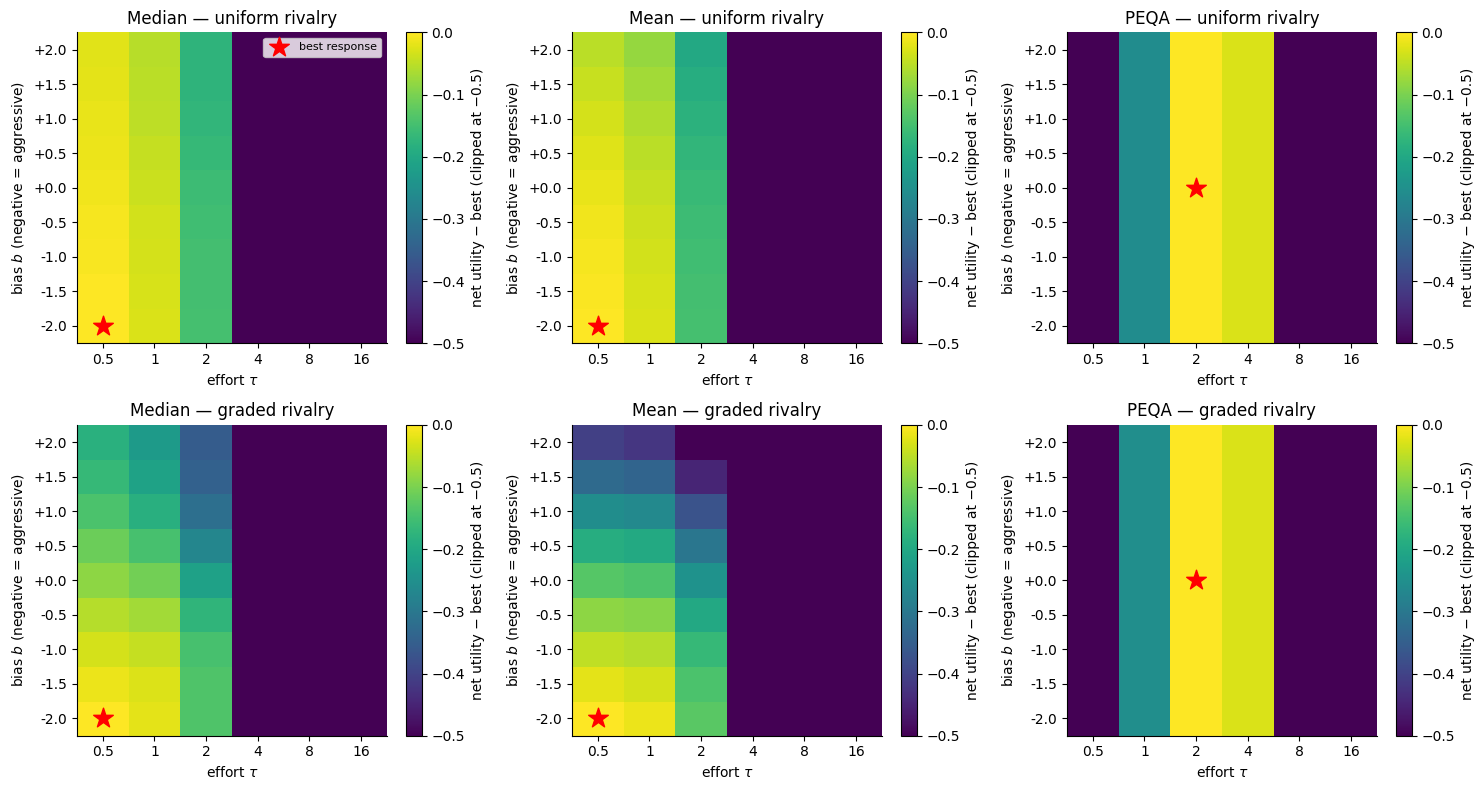

[saved] ./peer_grading_outputs/plots/expD_incentive_to_shade.png


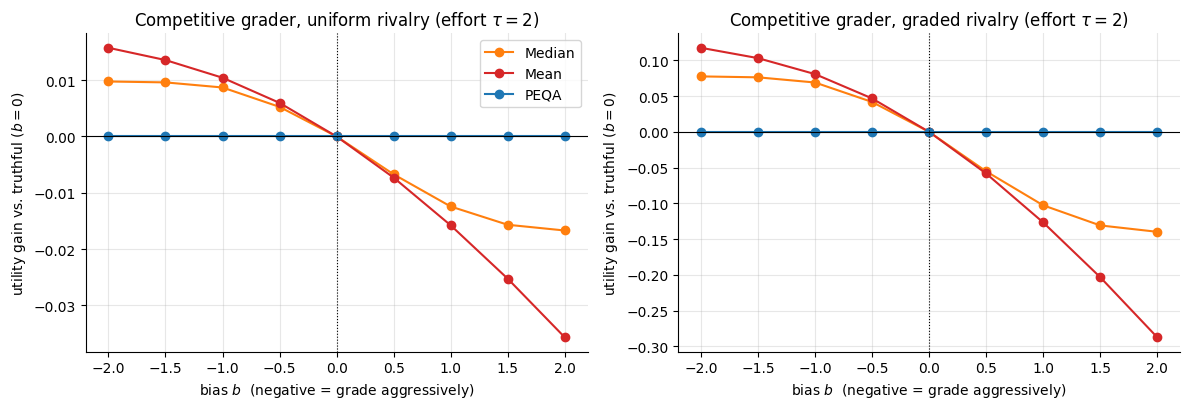

,rivalry,mechanism,best_bias,bias_irrelevant,best_tau,gain_from_shading,spread_over_bias
0,uniform,Median,-2.0,False,0.5,0.0104,0.0223
1,uniform,Mean,-2.0,False,0.5,0.0172,0.0514
2,uniform,PEQA,0.0,True,2.0,0.0000,0.0000
3,graded,Median,-2.0,False,0.5,0.0850,0.1828
4,graded,Mean,-2.0,False,0.5,0.1324,0.4060
5,graded,PEQA,0.0,True,2.0,0.0000,0.0000


[saved] ./peer_grading_outputs/data/expD_best_responses.csv


In [18]:
W_TOTAL = 1.0
D_BIAS = np.linspace(-2, 2, 9)
D_TAU  = [0.5, 1, 2, 4, 8, 16]
TAU_OTHERS = 2.0

def rival_weights(kind, e, focal):
    n = GCFG.n
    w = np.zeros(n)
    if kind == "uniform":
        w[:] = W_TOTAL / (n - 1)
    else:                                              # all weight on the non-probe papers she grades
        idx = np.where(e["A"][focal] & ~e["ip"])[0]
        w[idx] = W_TOTAL / len(idx)
    w[focal] = 0.0
    return w

def competitive_utility(mech, e, focal, b, tau, wv, tau_o=TAU_OTHERS, regrade=True):
    tv = np.full(GCFG.n, tau_o); tv[focal] = tau
    bv = np.zeros(GCFG.n); bv[focal] = b
    Y = build_reports(e["y"], e["A"], bv, tv, e["z"])
    o = mech_outcome(mech, Y, e["A"], e["ip"], e["y"], GCFG, ALPHA, regrade)
    return o["g"][focal] + o["t"][focal] - (wv * (o["g"] + o["t"])).sum()

def argmax_prefer_truthful(U, tol=1e-9):
    """Best (bias, effort) cell; among bias values that tie (within tol) pick the one closest to 0 (truthful)."""
    jt = int(np.argmax(U.max(axis=0)))
    cand = np.where(U[:, jt] >= U[:, jt].max() - tol)[0]
    ib = int(cand[np.argmin(np.abs(D_BIAS[cand]))])
    return ib, jt

t0 = time.time()
resD = {}
rows = []
for kind in ("uniform", "graded"):
    for mech in ("Median", "Mean", "PEQA"):
        U = np.zeros((len(D_BIAS), len(D_TAU)))
        for i, b in enumerate(D_BIAS):
            for j, tau in enumerate(D_TAU):
                U[i, j] = np.mean([competitive_utility(mech, e, 0, b, tau, rival_weights(kind, e, 0)) for e in envs]) \
                          - effort_cost(tau, KAPPA)
        resD[(kind, mech)] = U
        for i, b in enumerate(D_BIAS):
            for j, tau in enumerate(D_TAU):
                rows.append(dict(rivalry=kind, mechanism=mech, bias=b, tau=tau, net_utility=U[i, j]))
log(f"Experiment D finished in {time.time()-t0:.1f}s")
save_df(pd.DataFrame(rows), "expD_competitive_grader_utilities")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for r_, kind in enumerate(("uniform", "graded")):
    for c_, mech in enumerate(("Median", "Mean", "PEQA")):
        U = resD[(kind, mech)]; ax = axes[r_, c_]
        im = ax.imshow(U - U.max(), aspect="auto", origin="lower", cmap="viridis", vmin=-0.5, vmax=0.0)   # clip: zoom on the optimum
        ib, jt = argmax_prefer_truthful(U)
        ax.scatter([jt], [ib], marker="*", s=220, color="red", label="best response")
        ax.set_xticks(range(len(D_TAU))); ax.set_xticklabels(D_TAU)
        ax.set_yticks(range(len(D_BIAS))); ax.set_yticklabels([f"{b:+.1f}" for b in D_BIAS])
        ax.set_xlabel("effort $\\tau$"); ax.set_ylabel("bias $b$ (negative = aggressive)")
        ax.set_title(f"{mech} — {kind} rivalry"); ax.grid(False)
        plt.colorbar(im, ax=ax, label="net utility − best (clipped at −0.5)")
        if r_ == 0 and c_ == 0: ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); savefig("expD_competitive_grader_heatmaps")

# ---- the incentive to shade, shown directly: utility vs bias at a fixed (moderate) effort tau = 2
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
j2 = D_TAU.index(2)
for ax, kind in zip(axes, ("uniform", "graded")):
    for mech, col in (("Median", "tab:orange"), ("Mean", "tab:red"), ("PEQA", "tab:blue")):
        U = resD[(kind, mech)][:, j2]
        ax.plot(D_BIAS, U - U[D_BIAS.tolist().index(0.0)], "o-", color=col, label=mech)
    ax.axhline(0, color="k", lw=0.8); ax.axvline(0, color="k", lw=0.8, ls=":")
    ax.set_xlabel("bias $b$  (negative = grade aggressively)"); ax.set_ylabel("utility gain vs. truthful ($b=0$)")
    ax.set_title(f"Competitive grader, {kind} rivalry (effort $\\tau=2$)")
axes[0].legend()
plt.tight_layout(); savefig("expD_incentive_to_shade")

br = []
for (kind, mech), U in resD.items():
    ib, jt = argmax_prefer_truthful(U)
    flat = bool((U[:, jt].max() - U[:, jt].min()) < 1e-9)
    br.append(dict(rivalry=kind, mechanism=mech, best_bias=D_BIAS[ib], bias_irrelevant=flat, best_tau=D_TAU[jt],
                   gain_from_shading=U[ib, jt] - U[D_BIAS.tolist().index(0.0), jt],      # best bias vs truthful bias at same effort
                   spread_over_bias=(U[:, jt].max() - U[:, jt].min())))
brdf = pd.DataFrame(br); display(brdf.round(4)); save_df(brdf, "expD_best_responses")

**Reading Experiment D.**
* **Median / Mean**: the best response uses the most negative bias (the star sits on the bottom edge of the grid): the competitive grader strictly gains by shading, and the gain grows with the weight she puts on the papers she grades ("graded" rivalry). Her best effort is at the lowest tested value, because a precise report earns nothing. (The *median* shows a smaller gain than the *mean* because it only moves when she is pivotal; with regrading, a score pushed below the truth is reverted to $y_j$, which caps the damage.)
* **PEQA**: utility is flat along the bias axis (differences are zero up to floating-point error — EPBI; the star is drawn at the truthful bias $b=0$ among the tied best responses), so the competitive grader has **no reason to distort her reports**; and the best response has an interior effort level, because her performance score rewards precision. Her rivals' performance scores $t_k$ also appear in her utility, but Theorem 1 shows these effects never outweigh her own marginal contribution when $\sum_kw_{k}\le1$.

## Part 7 — Experiment E: brute-force verification on a tiny instance

**Goal (project text).** On a tiny instance — **3 graders, 3 submissions, discretised reports** — confirm by *exhaustive enumeration* that (i) under PEQA, truthful reporting (no bias) with high effort is a best response, and (ii) under the median mechanism it is not.

**Instance.** Graders A, B, C own submissions 1, 2, 3; nobody grades her own paper, so A grades {2,3}, B grades {1,3}, C grades {1,2}. Each submission has **two questions** (this gives each grader two observations on her probe paper, the minimum needed to estimate a variance). Submissions 1 and 2 are **probes** (instructor-graded), submission 3 is the only **non-probe**; its score is aggregated from A's and B's reports. (C grades two probes and no non-probe, so C is inert.)

| | true scores (q1, q2) |
|---|---|
| submission 1 (probe, owner A) | (2.5, 3.0) |
| submission 2 (probe, owner B) | (2.0, 3.0) |
| submission 3 (non-probe, owner C) | (2.5, 2.0) |

**Discretisation.** A grader's signal on a question is the true score plus a noise offset from the grid $\{-1,-\tfrac12,0,\tfrac12,1\}$ with probabilities $\propto e^{-x^2/2\sigma^2}$; effort sets $\sigma$: *low* 0.8, *medium* 0.5 (B's default), *high* 0.3. A's **strategy** = (effort, shift $s\in\{-1,-\tfrac12,0,\tfrac12,1\}$): she reports signal $+s$ (so $s=0$ is *truthful*). All $5^8=390{,}625$ signal profiles (A: 2+2 signals, B: 2+2 signals) are enumerated **exactly** — no sampling.

**Mechanisms (same instance, same regrading by C):**
* **PEQA**: ISWDM with $\hat b,\hat\tau$ from the probe paper ($\hat\tau_i=1/(\sum(\cdot)^2+\epsilon)$, $\epsilon=0.1$ — a small smoothing because with 2 observations on a discrete grid the residual can be exactly 0), prior weight $\sqrt\gamma=2$, performance score $t_i=\alpha\sum_q (W_q-W_q^{(-i)})$, $\alpha=4$.
* **Median**: median of {A's report, B's report, a *phantom* report at the prior mean $\mu$} for each question. (With only two peer reports the plain median would be the mean; the phantom voter is the standard device to keep the generalised median rule well defined and strategyproof for single-peaked agents.) No performance score.
* **Mean**: average of the two reports (reference).

**Competitive grader.** A's utility $=g_A+t_A-\tfrac12(g_B+t_B)-\tfrac12(g_C+t_C)-\text{cost}(\text{effort})$ — total rival weight 1 — and, for comparison, the non-competitive case ($w=0$). Cost of *high* effort = $\lambda\times$ PEQA's benefit of high effort, with $\lambda=0.5$ (so, under PEQA, high effort is worth it).

PEQA benefit of high effort (competitive A, B honest): 0.2603  ->  cost(high) = 0.1301
[17:25:11] Brute-force tables computed in 1.9s
[saved] ./peer_grading_outputs/plots/expE_bruteforce_tables.png


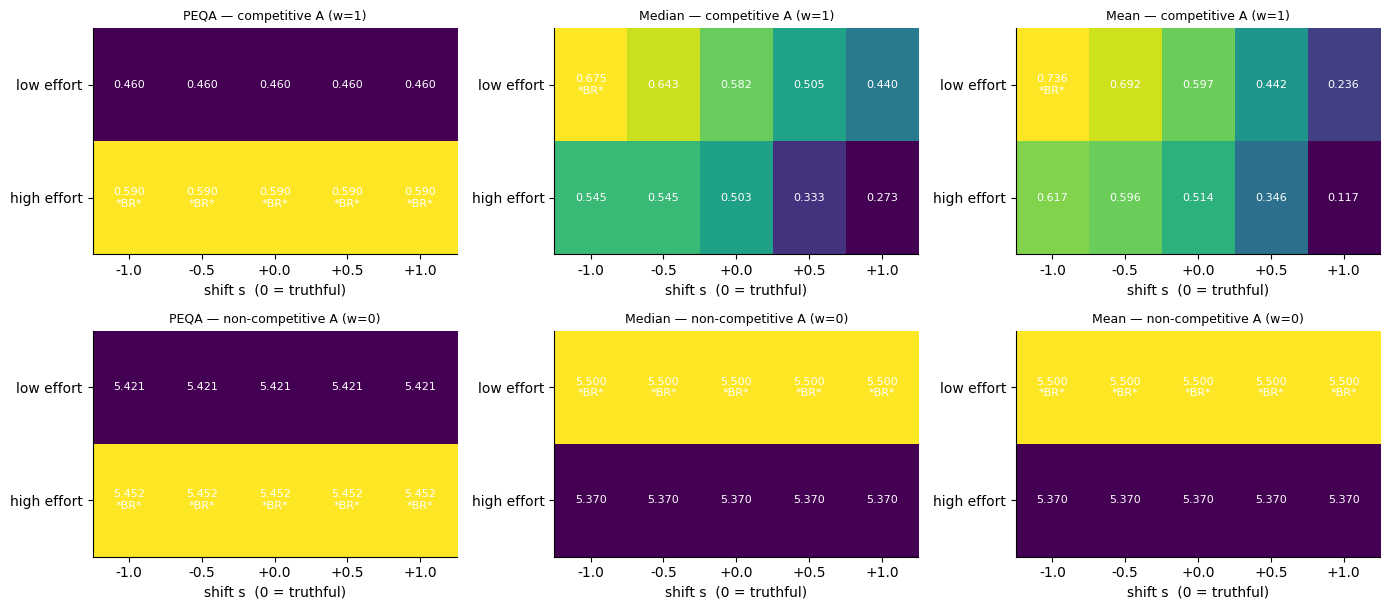

,competitive,mechanism,truthful_high_effort_is_BR,best_responses
0,True,PEQA,True,"(high, -1.0), (high, -0.5), (high, +0.0), (hig..."
1,True,Median,False,"(low, -1.0)"
2,True,Mean,False,"(low, -1.0)"
3,False,PEQA,True,"(high, -1.0), (high, -0.5), (high, +0.0), (hig..."
4,False,Median,False,"(low, -1.0), (low, -0.5), (low, +0.0), (low, +..."
5,False,Mean,False,"(low, -1.0), (low, -0.5), (low, +0.0), (low, +..."


[saved] ./peer_grading_outputs/data/expE_best_response_summary.csv


In [19]:
OFFS   = np.array([-1.0, -0.5, 0.0, 0.5, 1.0])
SDS    = {"low": 0.8, "med": 0.5, "high": 0.3}
SHIFTS = [-1.0, -0.5, 0.0, 0.5, 1.0]
T_MU, T_SG, T_EPS, T_ALPHA = 2.5, 2.0, 0.1, 4.0            # prior mean, sqrt(gamma), smoothing, alpha
y_p0 = np.array([2.5, 3.0]); y_p1 = np.array([2.0, 3.0]); y_np = np.array([2.5, 2.0])
PAIRS = np.array(list(itertools.product(range(5), repeat=2)))       # 25 signal pairs for one 2-question paper
OFFP  = OFFS[PAIRS]                                                 # (25, 2) noise offsets

def pair_pmf(effort):
    p = np.exp(-OFFS ** 2 / (2 * SDS[effort] ** 2)); p = p / p.sum()
    return p[PAIRS[:, 0]] * p[PAIRS[:, 1]]

# state axes: (A's probe signals, A's NP signals, B's probe signals, B's NP signals) x (question)
a1 = OFFP[:, None, None, None, :]; a2 = OFFP[None, :, None, None, :]
b0 = OFFP[None, None, :, None, :]; b2 = OFFP[None, None, None, :, :]

def tiny_utilities(mech, a_shift, b_shift, w_total=1.0, regrade=True):
    """Utility of A in every one of the 5^8 signal states -> arrays (25,25,25,25): (non-competitive, competitive)
       (before subtracting effort cost)."""
    def est(o):                                    # probe estimates; the shift cancels in the de-biased report
        m = o.mean(-1); ss = ((o - m[..., None]) ** 2).sum(-1)
        return m, 1.0 / (ss + T_EPS)
    mA, tA = est(a1); mB, tB = est(b0)
    sA, sB = np.sqrt(tA)[..., None], np.sqrt(tB)[..., None]
    def agg(parts):
        num, den = T_SG * T_MU, T_SG
        for s, d in parts: num = num + s * d; den = den + s
        return num / den
    Wf = lambda r: -((r - (np.where(r < y_np, y_np, r) if regrade else y_np)) ** 2)
    gA, gB, wp = y_p0.sum(), y_p1.sum(), w_total / 2.0
    if mech == "PEQA":
        dA = y_np + a2 - mA[..., None]             # = y + (a2 + shift_A) - (mean(a1) + shift_A)   (shift cancels exactly)
        dB = y_np + b2 - mB[..., None]
        r = agg([(sA, dA), (sB, dB)]); W = Wf(r)
        tAv = T_ALPHA * (W - Wf(agg([(sB, dB)]))).sum(-1)
        tBv = T_ALPHA * (W - Wf(agg([(sA, dA)]))).sum(-1)
    else:
        repA = y_np + a2 + a_shift; repB = y_np + b2 + b_shift
        if mech == "Median":
            r = np.median(np.stack(np.broadcast_arrays(repA, repB, np.full(np.broadcast(repA, repB).shape, T_MU))), 0)
        else:
            r = (repA + repB) / 2
        tAv = tBv = 0.0
    gC = (np.maximum(r, y_np) if regrade else r).sum(-1)
    return gA + tAv + 0 * gC, gA + tAv - wp * (gB + tBv + gC)

def expected_utility(mech, a_eff, a_shift, b_eff, b_shift, **kw):
    pA, pB = pair_pmf(a_eff), pair_pmf(b_eff)
    nc, cp = tiny_utilities(mech, a_shift, b_shift, **kw)
    return (np.einsum("i,j,k,l,ijkl->", pA, pA, pB, pB, nc), np.einsum("i,j,k,l,ijkl->", pA, pA, pB, pB, cp))

STRATS = [(e_, s_) for e_ in ("low", "high") for s_ in SHIFTS]
MECHS = ["PEQA", "Median", "Mean"]

# ---- cost of high effort: lambda x PEQA benefit of high effort (B honest, medium effort)
LAMBDA = 0.5
gap = expected_utility("PEQA", "high", 0.0, "med", 0.0)[1] - expected_utility("PEQA", "low", 0.0, "med", 0.0)[1]
COST = {"low": 0.0, "high": LAMBDA * gap}
print(f"PEQA benefit of high effort (competitive A, B honest): {gap:.4f}  ->  cost(high) = {COST['high']:.4f}")

t0 = time.time()
tabs = {}
for comp in (True, False):
    for mech in MECHS:
        tabs[(comp, mech)] = np.array([[expected_utility(mech, e_, s_, "med", 0.0, w_total=1.0 if comp else 0.0)[1] - COST[e_]
                                        for s_ in SHIFTS] for e_ in ("low", "high")])
log(f"Brute-force tables computed in {time.time()-t0:.1f}s")

fig, axes = plt.subplots(2, 3, figsize=(14, 6.2))
for r_, comp in enumerate((True, False)):
    for c_, mech in enumerate(MECHS):
        U = tabs[(comp, mech)]; ax = axes[r_, c_]
        im = ax.imshow(U, aspect="auto", cmap="viridis"); ax.grid(False)
        best = np.isclose(U, U.max(), atol=1e-9)
        for (i, j), v in np.ndenumerate(U):
            ax.text(j, i, f"{v:.3f}" + ("\n*BR*" if best[i, j] else ""), ha="center", va="center", color="w", fontsize=8)
        ax.set_xticks(range(5)); ax.set_xticklabels([f"{s:+.1f}" for s in SHIFTS]); ax.set_yticks([0, 1]); ax.set_yticklabels(["low effort", "high effort"])
        ax.set_xlabel("shift s  (0 = truthful)"); ax.set_title(f"{mech} — {'competitive A (w=1)' if comp else 'non-competitive A (w=0)'}", fontsize=9)
plt.tight_layout(); savefig("expE_bruteforce_tables")

summ = []
for (comp, mech), U in tabs.items():
    best = np.isclose(U, U.max(), atol=1e-9)
    truthful_high = bool(best[1, SHIFTS.index(0.0)])
    bests = [f"({'high' if i else 'low'}, {SHIFTS[j]:+.1f})" for i, j in zip(*np.where(best))]
    summ.append(dict(competitive=comp, mechanism=mech, truthful_high_effort_is_BR=truthful_high, best_responses=", ".join(bests)))
summdf = pd.DataFrame(summ); display(summdf); save_df(summdf, "expE_best_response_summary")

In [20]:
# ---- print the best responses of the tiny instance in full -------------------------------------------------------
print("Expected NET utility of grader A (B honest, medium effort) for every strategy (effort, shift); the best response(s) are listed under each table\n")
for comp in (True, False):
    print(f"########  {'COMPETITIVE grader (rival weight 1)' if comp else 'NON-competitive grader (w = 0)'}  ########")
    for mech in MECHS:
        U = tabs[(comp, mech)]
        best = np.isclose(U, U.max(), atol=1e-9)
        table = pd.DataFrame(U, index=["low effort", "high effort"], columns=[f"s={s:+.1f}" for s in SHIFTS]).round(4)
        print(f"\n{mech}:"); print(table.to_string())
        print("best response(s):", [(("high" if i else "low"), SHIFTS[j]) for i, j in zip(*np.where(best))])
        print("truthful (s=0) + high effort is a best response:", bool(best[1, SHIFTS.index(0.0)]))
    print()

Expected NET utility of grader A (B honest, medium effort) for every strategy (effort, shift); the best response(s) are listed under each table

########  COMPETITIVE grader (rival weight 1)  ########

PEQA:
             s=-1.0  s=-0.5  s=+0.0  s=+0.5  s=+1.0
low effort   0.4603  0.4603  0.4603  0.4603  0.4603
high effort  0.5904  0.5904  0.5904  0.5904  0.5904
best response(s): [('high', -1.0), ('high', -0.5), ('high', 0.0), ('high', 0.5), ('high', 1.0)]
truthful (s=0) + high effort is a best response: True

Median:
             s=-1.0  s=-0.5  s=+0.0  s=+0.5  s=+1.0
low effort   0.6753  0.6432  0.5819  0.5054  0.4400
high effort  0.5452  0.5446  0.5031  0.3326  0.2732
best response(s): [('low', -1.0)]
truthful (s=0) + high effort is a best response: False

Mean:
             s=-1.0  s=-0.5  s=+0.0  s=+0.5  s=+1.0
low effort   0.7355  0.6919  0.5969  0.4419  0.2355
high effort  0.6174  0.5955  0.5141  0.3455  0.1174
best response(s): [('low', -1.0)]
truthful (s=0) + high effort is a b

In [21]:
# ---------------------------------------------------------------------------------------------
#  Stronger checks: dominance over ALL strategies of B, exact EPBI, and ex-post EPRM
# ---------------------------------------------------------------------------------------------
B_STRATS = [(e_, s_) for e_ in ("low", "med", "high") for s_ in SHIFTS]
dom = []
for mech in MECHS:
    ok = 0
    for b_eff, b_shift in B_STRATS:
        U = np.array([[expected_utility(mech, e_, s_, b_eff, b_shift)[1] - COST[e_] for s_ in SHIFTS] for e_ in ("low", "high")])
        ok += bool(np.isclose(U[1, SHIFTS.index(0.0)], U.max(), atol=1e-9))
    dom.append(dict(mechanism=mech, B_strategies_tested=len(B_STRATS), truthful_high_effort_BR_in=ok))
domdf = pd.DataFrame(dom)
print("(i) Is (truthful, high effort) a best response for competitive A against EVERY strategy of B?")
display(domdf); save_df(domdf, "expE_dominance_check")

# exact EPBI under PEQA: expected utility identical for every shift (all effort levels, competitive and not)
diffs = []
for e_ in ("low", "med", "high"):
    base_ = expected_utility("PEQA", e_, 0.0, "med", 0.0)
    for s_ in SHIFTS:
        v = expected_utility("PEQA", e_, s_, "med", 0.0)
        diffs.append(max(abs(v[0] - base_[0]), abs(v[1] - base_[1])))
print(f"(ii) EPBI under PEQA: max |U(shift s) - U(shift 0)| over all shifts/efforts = {max(diffs):.2e}")
assert max(diffs) < 1e-9

# ex-post EPRM: for EVERY realised report profile of B (25 x 25 = 625 profiles), A's expectation over HER OWN noise
pl, ph = pair_pmf("low"), pair_pmf("high")
rows = []
for comp_i, comp in enumerate((1.0, 0.0)):
    for s_ in SHIFTS:
        nc, cp = tiny_utilities("PEQA", s_, 0.0, w_total=comp)
        U = cp
        ex_low  = np.einsum("i,j,ijkl->kl", pl, pl, U)
        ex_high = np.einsum("i,j,ijkl->kl", ph, ph, U)
        rows.append(dict(competitive=bool(comp), A_shift=s_, B_profiles=ex_low.size,
                         share_with_high_ge_low=float(np.mean(ex_high >= ex_low - 1e-12)),
                         min_gain_of_high_effort=float((ex_high - ex_low).min())))
epdf = pd.DataFrame(rows)
print("(iii) Ex-post reliability monotonicity under PEQA (high vs low effort, for every realised report profile of B):")
display(epdf.round(4)); save_df(epdf, "expE_expost_EPRM")
assert (epdf.share_with_high_ge_low == 1.0).all()
print("\nAll brute-force checks passed.")

(i) Is (truthful, high effort) a best response for competitive A against EVERY strategy of B?


,mechanism,B_strategies_tested,truthful_high_effort_BR_in
0,PEQA,15,15
1,Median,15,0
2,Mean,15,0


[saved] ./peer_grading_outputs/data/expE_dominance_check.csv
(ii) EPBI under PEQA: max |U(shift s) - U(shift 0)| over all shifts/efforts = 0.00e+00
(iii) Ex-post reliability monotonicity under PEQA (high vs low effort, for every realised report profile of B):


,competitive,A_shift,B_profiles,share_with_high_ge_low,min_gain_of_high_effort
0,True,-1.0,625,1.0,0.1834
1,True,-0.5,625,1.0,0.1834
2,True,0.0,625,1.0,0.1834
3,True,0.5,625,1.0,0.1834
4,True,1.0,625,1.0,0.1834
5,False,-1.0,625,1.0,-0.0000
6,False,-0.5,625,1.0,-0.0000
7,False,0.0,625,1.0,-0.0000
8,False,0.5,625,1.0,-0.0000
9,False,1.0,625,1.0,-0.0000


[saved] ./peer_grading_outputs/data/expE_expost_EPRM.csv

All brute-force checks passed.


**Reading Experiment E.**
1. **PEQA**: all five shifts give *exactly* the same expected utility (EPBI), and high effort is strictly better than low effort whenever its cost is below the benefit — so *(truthful, high effort)* is a best response (with ties across shifts — "truthful" is among the best responses, not the only one). It remains a best response against **all 15** strategies of B (dominance), and high effort beats low effort for **every** realised report profile of the other grader (ex-post EPRM), for competitive and non-competitive A.
2. **Median** (competitive A): the best response is the lowest shift ($s=-1$): truthful reporting is **not** a best response, and effort has (almost) no value, so low effort is preferred as soon as it has any cost. Without competition ($w=0$) A's payoff does not depend on her reports at all, so every *shift* ties (truthful reporting is weakly optimal — the median is trivially harmless) but she still picks **low effort**, because nothing pays for precision.
3. **Mean** behaves like the median for the competitive grader (even more strongly: every report moves the outcome).

## Part 7b — Experiment F: sensitivity to the number of probes, papers per grader and number of graders

Everything above used one design ($n=60$, $K=8$, $\ell=12$). Here we change the **design parameters** and see how the recovery-error plots (Exp. A/B) and the effort game (Exp. C2) move.

**What each design parameter does (paper Algorithm 1):**

| parameter | what changes | expected effect |
|---|---|---|
| $\ell$ (probes) | $n-\ell$ non-probe papers remain; each non-probe paper gets $\approx nK/2/(n-\ell)$ graders (more as $\ell$ grows); probe papers get $\approx nK/2/\ell$ graders. **Each grader still sees exactly $K/2$ probes**, so the *quality of her $\hat b_i,\hat\tau_i$ does not depend on $\ell$* — $\ell$ mostly sets the instructor's grading workload and the constraint $K/2+1\le\ell\le n/(K/2+1)$. | small effect on accuracy; a cost to the instructor |
| $K$ (papers per grader) | $K/2$ probe observations per grader: $\hat b_i$ has noise $\sigma_i/\sqrt{K/2}$, $\hat\tau_i$ has $K/2-1$ degrees of freedom; also more graders per paper. Grading cost grows with $K$. | more accuracy for PEQA, and for every rule via more graders per paper; lower equilibrium effort per paper as total cost grows |
| $n$ (class size) | the number of graders per paper is $\approx K/2\cdot n/(n-\ell)$ — depends on $n$ only through the ratio $\ell/n$ | accuracy roughly flat once $\ell/n$ is fixed; the Mean/Median/PEQA ranking should not depend on $n$ |

**Two scenarios** are run: *baseline* (individual bias sd 0.5, no adversaries) and *stress* (10 % graders who always report 0, plus a common bias $\delta=1$). The second scenario is where the probes matter.

In the effort part (F4) we recompute the **symmetric Nash equilibrium** effort and the best response to others at $\tau=2$ for each design.

[17:25:52] Experiment F1-F3 finished in 23.8s
[saved] ./peer_grading_outputs/data/expF_F1_baseline.csv
[saved] ./peer_grading_outputs/data/expF_F2_baseline.csv
[saved] ./peer_grading_outputs/data/expF_F3_baseline.csv
[saved] ./peer_grading_outputs/data/expF_F1_stress.csv
[saved] ./peer_grading_outputs/data/expF_F2_stress.csv
[saved] ./peer_grading_outputs/data/expF_F3_stress.csv
[saved] ./peer_grading_outputs/plots/expF_sensitivity_recovery.png


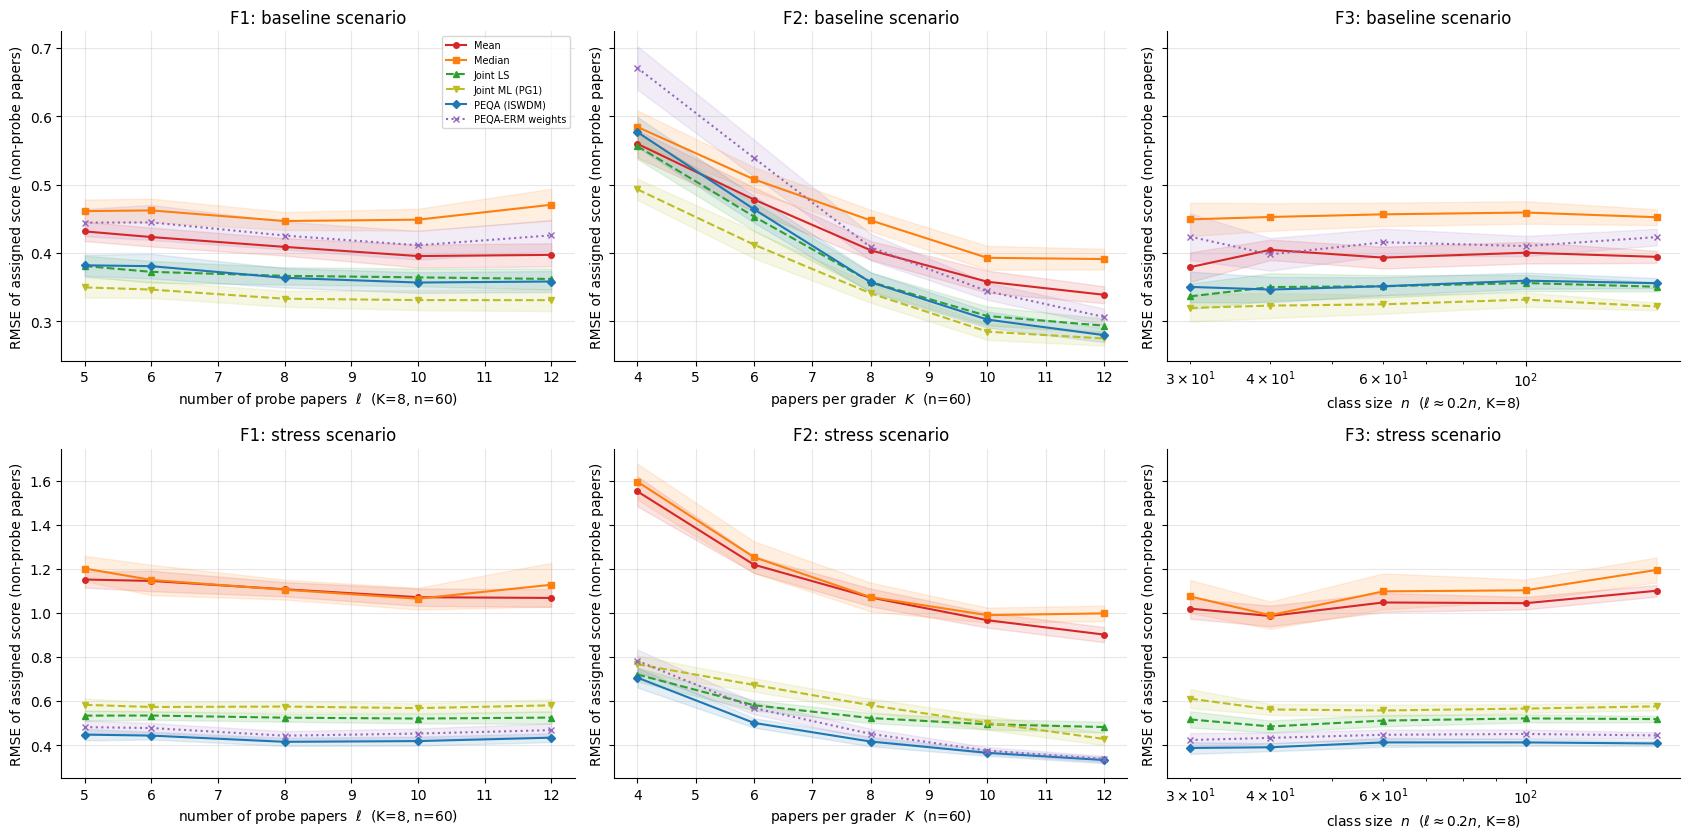

Graders per paper implied by the design  (n*K/2 / (n - l) for non-probe, n*K/2 / l for probe papers):


,sweep,value,K,probes,nonprobe_papers,graders_per_nonprobe,graders_per_probe
0,F1,5,8,5,55,4.36,48.0
1,F1,6,8,6,54,4.44,40.0
2,F1,8,8,8,52,4.62,30.0
3,F1,10,8,10,50,4.80,24.0
4,F1,12,8,12,48,5.00,20.0
5,F2,4,4,12,48,2.50,10.0
6,F2,6,6,12,48,3.75,15.0
7,F2,8,8,12,48,5.00,20.0
8,F2,10,10,10,50,6.00,30.0
9,F2,12,12,8,52,6.92,45.0


In [22]:
def feasible_probes(n, K, target=12):
    h = K // 2
    return int(min(max(target, h + 1), n // (h + 1)))

def run_cfg_list(xs, cfgs, reps, seed):
    rng = np.random.default_rng(seed); rows = []
    for x, cfg in zip(xs, cfgs):
        for rep in range(reps):
            rd = generate_round(cfg, rng)
            for name, m in evaluate_round(rd).items():
                rows.append(dict(value=x, rep=rep, rule=name, **m))
    return pd.DataFrame(rows)

SCEN = {"baseline": SimConfig(n=60, K=8, n_probes=12),
        "stress":   SimConfig(n=60, K=8, n_probes=12, adv_frac=0.1, adv_type="zero", bias_shift=1.0)}
REPS_F = 10 if QUICK_MODE else 30
t0 = time.time(); sens = {}
for sc, base_cfg in SCEN.items():
    # F1: number of probes (K = 8 fixed -> 5 <= l <= 12)
    ls = [5, 6, 8, 10, 12]
    sens[(sc, "F1")] = run_cfg_list(ls, [replace(base_cfg, n_probes=l) for l in ls], REPS_F, SEED + 31)
    # F2: papers per grader K  (l adjusted to stay feasible)
    Ks = [4, 6, 8, 10, 12]
    sens[(sc, "F2")] = run_cfg_list(Ks, [replace(base_cfg, K=k, n_probes=feasible_probes(base_cfg.n, k)) for k in Ks], REPS_F, SEED + 32)
    # F3: class size n (l = about 20 % of n)
    ns = [30, 40, 60, 100, 160]
    sens[(sc, "F3")] = run_cfg_list(ns, [replace(base_cfg, n=n_, n_probes=feasible_probes(n_, 8, target=round(0.2 * n_))) for n_ in ns], REPS_F, SEED + 33)
log(f"Experiment F1-F3 finished in {time.time()-t0:.1f}s")

xl = {"F1": "number of probe papers  $\\ell$  (K=8, n=60)", "F2": "papers per grader  $K$  (n=60)", "F3": "class size  $n$  ($\\ell\\approx0.2n$, K=8)"}
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5), sharey="row")
for r_, sc in enumerate(SCEN):
    for c_, key in enumerate(("F1", "F2", "F3")):
        df_ = sens[(sc, key)]; save_df(df_, f"expF_{key}_{sc}")
        plot_sweep(axes[r_, c_], summarize(df_), xl[key], f"{key}: {sc} scenario")
        axes[r_, c_].set_xscale("log" if key == "F3" else "linear")
axes[0, 0].legend(fontsize=7); plt.tight_layout(); savefig("expF_sensitivity_recovery")

print("Graders per paper implied by the design  (n*K/2 / (n - l) for non-probe, n*K/2 / l for probe papers):")
rows = []
for key, xs_, cfgs_ in (("F1", ls, [replace(SimConfig(), n_probes=l) for l in ls]), ("F2", Ks, [replace(SimConfig(), K=k, n_probes=feasible_probes(60, k)) for k in Ks])):
    for x, c_ in zip(xs_, cfgs_):
        rows.append(dict(sweep=key, value=x, K=c_.K, probes=c_.n_probes, nonprobe_papers=c_.n - c_.n_probes,
                         graders_per_nonprobe=c_.n * c_.K / 2 / (c_.n - c_.n_probes), graders_per_probe=c_.n * c_.K / 2 / c_.n_probes))
display(pd.DataFrame(rows).round(2))

[saved] ./peer_grading_outputs/plots/expF_heatmap_K_probes.png


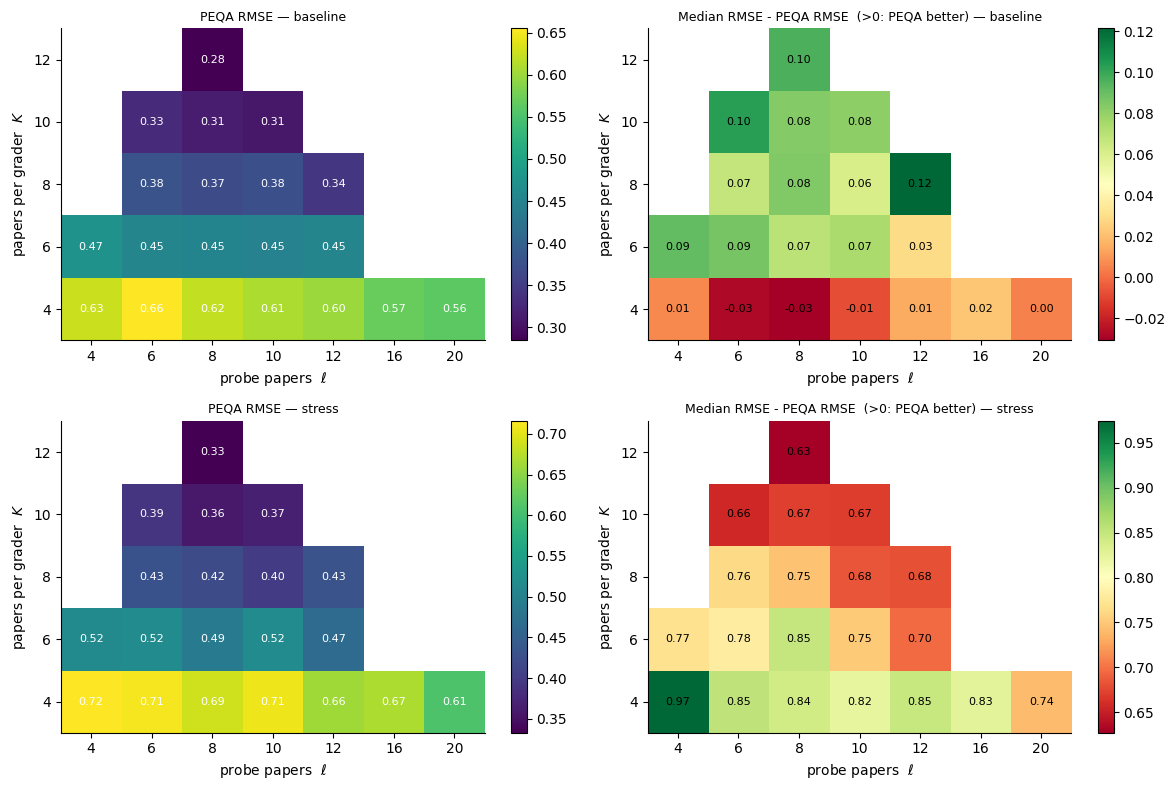

[saved] ./peer_grading_outputs/data/expF_heatmap_K_probes.csv


In [23]:
# ---- F2b: heat-map over the (K, l) grid, n = 60 -------------------------------------------------------------------------
Kg = [4, 6, 8, 10, 12]; Lg = [4, 6, 8, 10, 12, 16, 20]
res_grid = {sc: {"PEQA": np.full((len(Kg), len(Lg)), np.nan), "Median": np.full((len(Kg), len(Lg)), np.nan)} for sc in SCEN}
rng_g = np.random.default_rng(SEED + 40)
for sc, base_cfg in SCEN.items():
    for a_, k in enumerate(Kg):
        for b_, l in enumerate(Lg):
            if l < k // 2 + 1 or l > base_cfg.n // (k // 2 + 1): continue          # infeasible design
            cfg_ = replace(base_cfg, K=k, n_probes=l)
            ev = [evaluate_round(generate_round(cfg_, rng_g), ["PEQA (ISWDM)", "Median"]) for _ in range(max(6, REPS_F // 2))]
            res_grid[sc]["PEQA"][a_, b_] = np.mean([e["PEQA (ISWDM)"]["rmse"] for e in ev])
            res_grid[sc]["Median"][a_, b_] = np.mean([e["Median"]["rmse"] for e in ev])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for r_, sc in enumerate(SCEN):
    for c_, (lab, M_) in enumerate((("PEQA RMSE", res_grid[sc]["PEQA"]), ("Median RMSE - PEQA RMSE  (>0: PEQA better)", res_grid[sc]["Median"] - res_grid[sc]["PEQA"]))):
        ax = axes[r_, c_]; im = ax.imshow(M_, cmap="viridis" if c_ == 0 else "RdYlGn", aspect="auto", origin="lower"); ax.grid(False)
        for (i, j), v in np.ndenumerate(M_):
            if not np.isnan(v): ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="w" if c_ == 0 else "k")
        ax.set_xticks(range(len(Lg))); ax.set_xticklabels(Lg); ax.set_yticks(range(len(Kg))); ax.set_yticklabels(Kg)
        ax.set_xlabel("probe papers  $\\ell$"); ax.set_ylabel("papers per grader  $K$"); ax.set_title(f"{lab} — {sc}", fontsize=9)
        plt.colorbar(im, ax=ax)
plt.tight_layout(); savefig("expF_heatmap_K_probes")
rows = [dict(scenario=sc, K=k, probes=l, peqa_rmse=res_grid[sc]["PEQA"][a_, b_], median_rmse=res_grid[sc]["Median"][a_, b_])
        for sc in SCEN for a_, k in enumerate(Kg) for b_, l in enumerate(Lg) if not np.isnan(res_grid[sc]["PEQA"][a_, b_])]
save_df(pd.DataFrame(rows), "expF_heatmap_K_probes")

[17:26:51] Experiment F4 finished in 53.8s


,sweep,value,K,probes,n,regrading,NE_effort,BR_to_tau2
0,probes l,5,8,5,40,False,3.120,3.971
1,probes l,5,8,5,40,True,2.466,2.832
2,probes l,6,8,6,40,False,3.081,3.874
3,probes l,6,8,6,40,True,2.331,2.568
4,probes l,7,8,7,40,False,2.949,3.651
5,probes l,7,8,7,40,True,2.215,2.395
6,probes l,8,8,8,40,False,3.058,3.893
7,probes l,8,8,8,40,True,2.338,2.605
8,K,4,4,8,40,False,4.969,6.275
9,K,4,4,8,40,True,3.700,4.870


[saved] ./peer_grading_outputs/data/expF4_effort_vs_design.csv
[saved] ./peer_grading_outputs/plots/expF_effort_vs_design.png


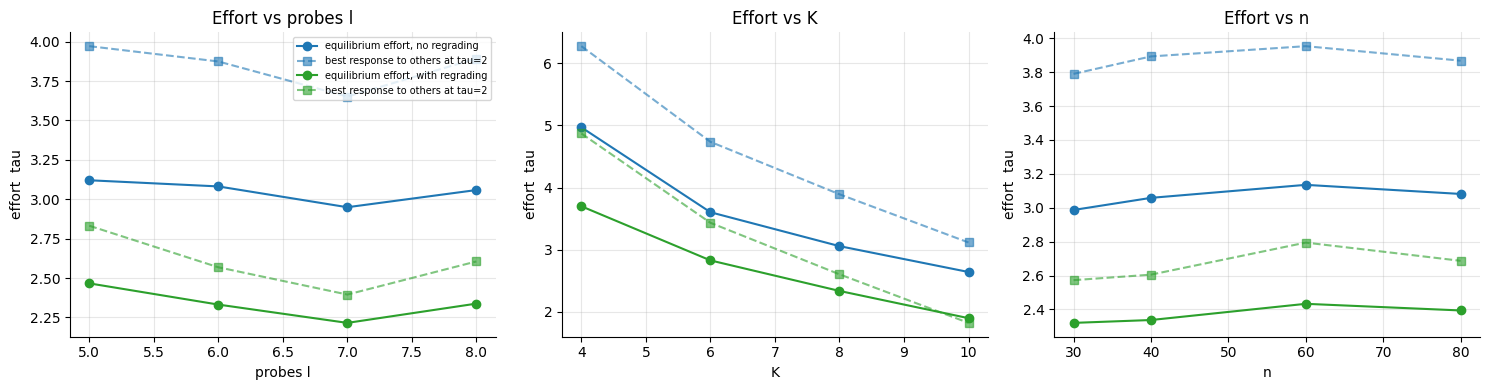

In [24]:
# ---- F4: effort equilibrium for different designs (n = 40 base game) ----------------------------------------------------
REPS_FE = 30 if QUICK_MODE else 80

def design_equilibrium(cfg, regrade, reps=REPS_FE, seed=SEED + 50, tau_ref=2.0):
    env_c = make_envs(cfg, reps, np.random.default_rng(seed))
    def br(tau_o):
        tv = np.full(cfg.n, tau_o)
        u = focal_t_curve(env_c, 0, TG, tv, cfg, ALPHA, regrade) - effort_cost(TG, KAPPA, cfg)
        k = int(np.argmax(u)); lo, hi = TG[max(k - 1, 0)], TG[min(k + 1, len(TG) - 1)]
        f = lambda lt: -(focal_t_curve(env_c, 0, [np.exp(lt)], tv, cfg, ALPHA, regrade)[0] - effort_cost(np.exp(lt), KAPPA, cfg))
        return float(np.exp(minimize_scalar(f, bounds=(np.log(lo), np.log(hi)), method="bounded", options=dict(xatol=1e-3)).x))
    g = lambda t: br(t) - t
    ne = brentq(g, 0.3, 20, xtol=1e-3) if g(0.3) * g(20) < 0 else np.nan
    return ne, br(tau_ref)

t0 = time.time(); rows = []
designs = [("probes l", l, SimConfig(n=40, K=8, n_probes=l)) for l in (5, 6, 7, 8)] + \
          [("K", k, SimConfig(n=40, K=k, n_probes=feasible_probes(40, k, 8))) for k in (4, 6, 8, 10)] + \
          [("n", n_, SimConfig(n=n_, K=8, n_probes=feasible_probes(n_, 8, round(0.2 * n_)))) for n_ in (30, 40, 60, 80)]
for sweep_name, val, cfg_ in designs:
    for rg in (False, True):
        ne, br2 = design_equilibrium(cfg_, rg)
        rows.append(dict(sweep=sweep_name, value=val, K=cfg_.K, probes=cfg_.n_probes, n=cfg_.n, regrading=rg, NE_effort=ne, BR_to_tau2=br2))
log(f"Experiment F4 finished in {time.time()-t0:.1f}s")
efdf = pd.DataFrame(rows); display(efdf.round(3)); save_df(efdf, "expF4_effort_vs_design")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, sweep_name in zip(axes, ("probes l", "K", "n")):
    for rg, col in ((False, "tab:blue"), (True, "tab:green")):
        d = efdf[(efdf.sweep == sweep_name) & (efdf.regrading == rg)]
        ax.plot(d.value, d.NE_effort, "o-", color=col, label=f"equilibrium effort, {'with' if rg else 'no'} regrading")
        ax.plot(d.value, d.BR_to_tau2, "s--", color=col, alpha=.6, label=f"best response to others at tau=2")
    ax.set_xlabel(sweep_name); ax.set_ylabel("effort  tau"); ax.set_title(f"Effort vs {sweep_name}")
axes[0].legend(fontsize=7); plt.tight_layout(); savefig("expF_effort_vs_design")

**Reading Experiment F** (numbers from the default full run; yours will differ slightly with the seed).

* **Number of probes $\ell$ (F1)** has only a *small* effect on accuracy. Each grader always sees $K/2$ probes, so her estimates $\hat b_i,\hat\tau_i$ are no better with more probe papers. What changes is the number of graders per non-probe paper ($4.4\to5.0$ as $\ell$ goes from 5 to 12), which helps *every* rule a little (baseline RMSE of PEQA $\approx0.38\to0.36$, Mean $0.43\to0.40$). So $\ell$ is mainly an instructor-workload decision: choose the smallest feasible $\ell\ge K/2+1$.
* **Papers per grader $K$ (F2)** is the parameter that matters. Going from $K=4$ to $K=12$ cuts PEQA's baseline RMSE from about $0.58$ to $0.28$, because (i) each grader has more probe observations, so $\hat b_i$ and $\hat\tau_i$ are more precise, and (ii) every paper has more graders. With $K=4$ (only two probes per grader, one degree of freedom for $\hat\tau_i$) PEQA is *not* better than the plain mean in the baseline scenario; from $K\approx6$ on it matches or beats Joint LS, and in the stress scenario it beats Mean/Median at every $K$. The heat-map shows the same picture: moving along $K$ changes the colours much more than moving along $\ell$.
* **Class size $n$ (F3)** hardly matters once $\ell/n$ is fixed: the number of graders per paper depends on $n$ only through that ratio, so RMSE is flat in $n$ and the ranking of the rules does not change.
* **Stress scenario caveat.** Joint LS looks decent here (RMSE $\approx0.5$) only by accident: its sum-to-zero bias constraint makes the *+1 common shift* and the *zero-reporting adversaries* partly cancel. Change `bias_shift` or `adv_frac` and it degrades (see A3/B); PEQA does not depend on such cancellations because the probes anchor the scale.
* **Effort (F4):** the equilibrium effort is nearly unchanged by $\ell$ and $n$ (it stays around $2.9$–$3.1$ without regrading), but it **falls with $K$** ($\approx5.0$ at $K=4$ to $\approx2.6$ at $K=10$). With more graders on each paper a single grader's marginal contribution to accuracy shrinks, while her total grading cost $Kc(\tau)$ grows. To keep effort high with large $K$, increase the performance-score weight $\alpha$ (re-run with a larger `ALPHA`).

**Design guidance:** use as many papers per grader as the workload allows (≥ 6–8), keep $\ell$ near the minimum $K/2+1$ up to what the instructor can grade, and do not worry about $n$.

## Part 7c — Experiment G: stress test of Hypothesis 4 (graders can tell probes from non-probes)

**What PEQA assumes (paper, Sec. 2.2 and Hypothesis 4).** A grader uses the *same* bias $b_i$ and reliability $\tau_i$ on probe and non-probe papers. This is what lets the mechanism transfer $(\hat b_i,\hat\tau_i)$, measured on probes, to the non-probe papers. The paper's classroom data did not reject it (p = 0.16–0.86).

**What if it fails?** Suppose a grader can *recognise* probes (e.g. probes are older exam papers, or are visibly different). A strategic grader could then behave well on probes and badly on non-probes. We model:

| parameter | meaning | default |
|---|---|---|
| `acc` | probability that a grader classifies a paper correctly (probe vs non-probe). `acc = 0.5`: cannot tell (H4 holds); `acc = 1`: perfect discrimination | swept 0.5 → 1 |
| `strat_frac` | share of graders who behave strategically on papers they believe are non-probes | 0.5 |
| `np_bias` | extra bias on believed non-probes (negative = grade aggressively) | −1.5 |
| `np_tau_factor` | multiplier of their reliability on believed non-probes (< 1 = they shirk) | 0.5 |

On papers believed to be probes, a strategic grader behaves like an honest one. With `acc = 0.5` her behaviour is the same mixture on probes and non-probes, so $\hat b_i,\hat\tau_i$ remain valid; as `acc` grows, probes become **unrepresentative** and PEQA's de-biasing and weighting use the wrong numbers: $\hat b_i\approx b_i$ (small) while the true bias on non-probes is $b_i+$`np_bias`.

We measure (G1) recovery error of all rules against `acc`; (G2) a heat-map of where PEQA stops beating the median as a function of `acc` and `np_bias`; (G3) whether the *paper's own test of H4* (probe vs non-probe bias and noise for the same grader) would detect the problem — an instructor needs to grade a few extra non-probe papers to run it.

[17:26:59] Experiment G1/G3 finished in 6.2s
[saved] ./peer_grading_outputs/data/expG1_h4_stress_rmse.csv
[saved] ./peer_grading_outputs/data/expG3_h4_detection.csv
[saved] ./peer_grading_outputs/plots/expG_hypothesis4_stress.png


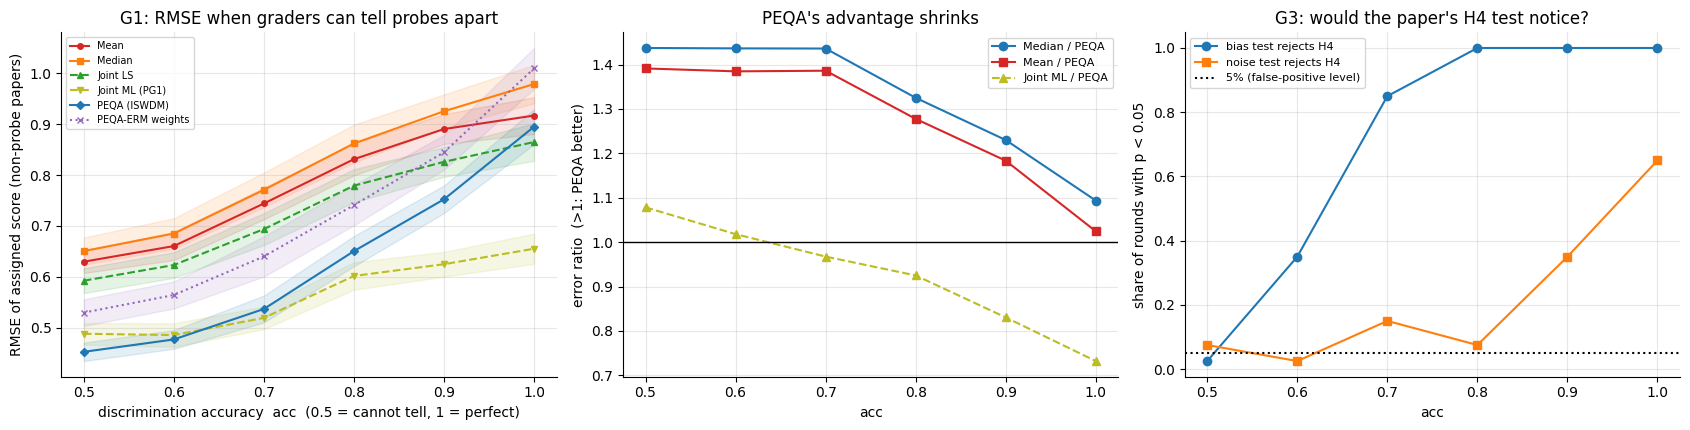

Mean RMSE per rule (rows = acc):


rule,Mean,Median,Joint LS,Joint ML (PG1),PEQA (ISWDM),PEQA degradation vs acc=0.5
value,,,,,,
0.5,0.630,0.651,0.592,0.488,0.453,0.000
0.6,0.660,0.685,0.623,0.486,0.477,0.054
0.7,0.744,0.771,0.694,0.519,0.537,0.186
0.8,0.831,0.862,0.779,0.602,0.651,0.437
0.9,0.890,0.925,0.826,0.625,0.752,0.662
1.0,0.917,0.979,0.865,0.655,0.895,0.977


Share of rounds in which the paper's H4 test (5% level) rejects:


,bias,noise
acc,,
0.5,0.02,0.08
0.6,0.35,0.02
0.7,0.85,0.15
0.8,1.00,0.08
0.9,1.00,0.35
1.0,1.00,0.65


In [25]:
from scipy import stats

def generate_round_h4(cfg, rng, acc=0.5, strat_frac=0.5, np_bias=-1.5, np_tau_factor=0.5):
    """Round in which strategic graders behave differently on papers they believe are non-probes."""
    n = cfg.n
    y = rng.normal(cfg.mu, cfg.sd_true, n)
    A, is_probe = make_assignment(n, cfg.K, cfg.n_probes, rng)
    bias, tau, _ = generate_population(cfg, rng)
    strat = rng.random(n) < strat_frac                                     # strategic graders
    u = rng.random((n, n))
    believes_probe = np.where(is_probe[None, :], u < acc, u < 1 - acc)     # her (noisy) classification
    shirk = strat[:, None] & ~believes_probe                              # strategic AND thinks "non-probe"
    bias_ij = bias[:, None] + np.where(shirk, np_bias, 0.0)
    tau_ij = tau[:, None] * np.where(shirk, np_tau_factor, 1.0)
    z = rng.standard_normal((n, n))
    Y = np.where(A, y[None, :] + bias_ij + z / np.sqrt(tau_ij), np.nan)
    return Round(cfg, y, A, is_probe, Y, bias, tau, strat)

def h4_test(rd):
    """The paper's test: for every grader compare her error on probes vs non-probes (paired across graders).
       Returns p-values for equal mean error (bias) and equal mean squared deviation (noise)."""
    P = rd.A & rd.is_probe[None, :]; N = rd.A & ~rd.is_probe[None, :]
    err = np.where(rd.A, rd.Y - rd.y[None, :], np.nan)
    bp = np.nanmean(np.where(P, err, np.nan), 1); bn = np.nanmean(np.where(N, err, np.nan), 1)
    vp = np.nanmean(np.where(P, (err - bp[:, None]) ** 2, np.nan), 1); vn = np.nanmean(np.where(N, (err - bn[:, None]) ** 2, np.nan), 1)
    return stats.ttest_rel(bp, bn).pvalue, stats.ttest_rel(vp, vn).pvalue, float(np.mean(bn - bp))

BASE_G = SimConfig(n=60, K=8, n_probes=12)
ACCS = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
REPS_G = 12 if QUICK_MODE else 40
rng_g1 = np.random.default_rng(SEED + 60)
rows, det = [], []
t0 = time.time()
for acc in ACCS:
    for rep in range(REPS_G):
        rd = generate_round_h4(BASE_G, rng_g1, acc=acc)
        for name, m in evaluate_round(rd).items():
            rows.append(dict(value=acc, rep=rep, rule=name, **m))
        pb, pv, gap = h4_test(rd)
        det.append(dict(acc=acc, rep=rep, p_bias=pb, p_noise=pv, true_bias_gap=gap))
log(f"Experiment G1/G3 finished in {time.time()-t0:.1f}s")
dfG1 = pd.DataFrame(rows); dfG3 = pd.DataFrame(det); save_df(dfG1, "expG1_h4_stress_rmse"); save_df(dfG3, "expG3_h4_detection")
sG1 = summarize(dfG1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
plot_sweep(axes[0], sG1, "discrimination accuracy  acc  (0.5 = cannot tell, 1 = perfect)", "G1: RMSE when graders can tell probes apart")
axes[0].legend(fontsize=7)
piv = sG1.pivot(index="value", columns="rule", values="mean")
axes[1].plot(piv.index, piv["Median"] / piv["PEQA (ISWDM)"], "o-", color="tab:blue", label="Median / PEQA")
axes[1].plot(piv.index, piv["Mean"] / piv["PEQA (ISWDM)"], "s-", color="tab:red", label="Mean / PEQA")
axes[1].plot(piv.index, piv["Joint ML (PG1)"] / piv["PEQA (ISWDM)"], "^--", color="tab:olive", label="Joint ML / PEQA")
axes[1].axhline(1, color="k", lw=1); axes[1].set_xlabel("acc"); axes[1].set_ylabel("error ratio  (>1: PEQA better)"); axes[1].set_title("PEQA's advantage shrinks"); axes[1].legend(fontsize=8)
rej = dfG3.groupby("acc").agg(bias=("p_bias", lambda p: np.mean(p < 0.05)), noise=("p_noise", lambda p: np.mean(p < 0.05)))
axes[2].plot(rej.index, rej["bias"], "o-", label="bias test rejects H4"); axes[2].plot(rej.index, rej["noise"], "s-", label="noise test rejects H4")
axes[2].axhline(0.05, color="k", ls=":", label="5% (false-positive level)"); axes[2].set_xlabel("acc"); axes[2].set_ylabel("share of rounds with p < 0.05")
axes[2].set_title("G3: would the paper's H4 test notice?"); axes[2].legend(fontsize=8)
plt.tight_layout(); savefig("expG_hypothesis4_stress")

tab = piv[["Mean", "Median", "Joint LS", "Joint ML (PG1)", "PEQA (ISWDM)"]].round(3)
tab["PEQA degradation vs acc=0.5"] = (piv["PEQA (ISWDM)"] / piv["PEQA (ISWDM)"].iloc[0] - 1).round(3)
print("Mean RMSE per rule (rows = acc):"); display(tab)
print("Share of rounds in which the paper's H4 test (5% level) rejects:"); display(rej.round(2))

[saved] ./peer_grading_outputs/plots/expG2_heatmap_break_even.png


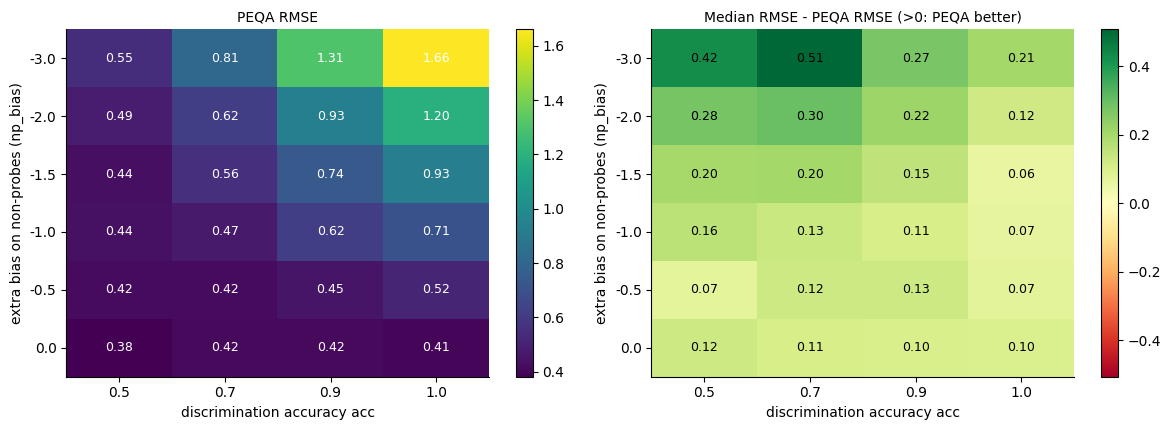

[saved] ./peer_grading_outputs/data/expG2_break_even_grid.csv


In [26]:
# ---- G2: where does PEQA stop beating the median?  (acc x np_bias grid) -----------------------------------------------
NPB = [0.0, -0.5, -1.0, -1.5, -2.0, -3.0]
accg = [0.5, 0.7, 0.9, 1.0]
rng_g2 = np.random.default_rng(SEED + 61); REPS_G2 = 6 if QUICK_MODE else 20
G2 = {k: np.zeros((len(NPB), len(accg))) for k in ("PEQA", "Median", "Mean")}
for i, nb_ in enumerate(NPB):
    for j, ac in enumerate(accg):
        ev = [evaluate_round(generate_round_h4(BASE_G, rng_g2, acc=ac, np_bias=nb_), ["PEQA (ISWDM)", "Median", "Mean"]) for _ in range(REPS_G2)]
        G2["PEQA"][i, j] = np.mean([e["PEQA (ISWDM)"]["rmse"] for e in ev])
        G2["Median"][i, j] = np.mean([e["Median"]["rmse"] for e in ev]); G2["Mean"][i, j] = np.mean([e["Mean"]["rmse"] for e in ev])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, (lab, M_, cm) in zip(axes, (("PEQA RMSE", G2["PEQA"], "viridis"), ("Median RMSE - PEQA RMSE (>0: PEQA better)", G2["Median"] - G2["PEQA"], "RdYlGn"))):
    vm = None if cm == "viridis" else np.abs(M_).max()
    im = ax.imshow(M_, cmap=cm, aspect="auto", origin="lower", vmin=None if vm is None else -vm, vmax=vm); ax.grid(False)
    for (i, j), v in np.ndenumerate(M_): ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="w" if cm == "viridis" else "k")
    ax.set_xticks(range(len(accg))); ax.set_xticklabels(accg); ax.set_yticks(range(len(NPB))); ax.set_yticklabels(NPB)
    ax.set_xlabel("discrimination accuracy acc"); ax.set_ylabel("extra bias on non-probes (np_bias)"); ax.set_title(lab, fontsize=10); plt.colorbar(im, ax=ax)
plt.tight_layout(); savefig("expG2_heatmap_break_even")
save_df(pd.DataFrame([dict(np_bias=NPB[i], acc=accg[j], peqa=G2["PEQA"][i, j], median=G2["Median"][i, j], mean=G2["Mean"][i, j])
                      for i in range(len(NPB)) for j in range(len(accg))]), "expG2_break_even_grid")

**Reading Experiment G** (default full run; strategic share 50 %, extra non-probe bias −1.5, reliability halved).

* **G1 — PEQA degrades, and fast.** With `acc = 0.5` (cannot tell, H4 true) PEQA has RMSE $\approx0.45$ and is the best rule. As discrimination improves it rises to $\approx0.90$ at `acc = 1` (about **+100 %**), because $\hat b_i,\hat\tau_i$ come from probes on which strategic graders behave well. Its advantage over the median shrinks from $\approx1.4\times$ to $\approx1.1\times$, and from `acc` $\approx0.7$ on the **Joint ML** estimator — which calibrates graders against each other on *all* papers — is better than PEQA. Mean, Median and Joint LS also get worse (the strategic behaviour on non-probes hurts every rule), but they never used the probes to begin with.
* **G2 — the break-even map.** PEQA still beats the median in most cells of the grid, so the mechanism is *degraded, not broken*, unless discrimination is nearly perfect **and** the non-probe misbehaviour is mild (then the gain is only ~0.05–0.1 RMSE points). Large misbehaviour (`np_bias` ≤ −2) hurts PEQA badly in absolute terms (RMSE > 1) even though the median is hurt more.
* **G3 — the problem is detectable.** The paper's own H4 test (paired comparison of each grader's bias on probes vs non-probes) has a false-positive rate of about 2–8 % when graders cannot tell probes apart, and rejects in $\approx35\%$ of rounds at `acc = 0.6`, $\approx85\%$ at `0.7` and essentially always from `0.8`. The noise test is much weaker (65 % at `acc = 1`). The test needs the instructor to grade a few **extra non-probe** papers (one batch is enough), so it is cheap insurance.
* **Caveat of the model:** the strategic behaviour here is *exogenous* (a fixed rule), not derived as an equilibrium; real graders who learn to spot probes could do something cleverer, so treat these numbers as an illustration of the *direction and speed* of the degradation.

**Practical mitigations:** make probes indistinguishable (same source, same format, drawn from the same pool as real submissions); randomise which papers are probes per grader; run the H4 test every round on a few extra non-probe papers, and fall back to Joint ML / median if it rejects.

## Part 8 — Summary and packaging of results

In [27]:
log("Building summary ...")
lines = []
lines.append("="*78)
lines.append("SUMMARY OF FINDINGS (numbers come from the runs above)")
lines.append("="*78)

# A
for nm, s, v in (("A1 individual bias, s_b=2.0", sA1, 2.0), ("A2 noise, sigma=2.5", sA2, 2.5), ("A3 common shift, delta=3.0", sA3, 3.0)):
    t_ = s[s.value == v].set_index("rule")["mean"].sort_values()
    lines.append(f"[{nm}] RMSE ranking (best->worst): " + " < ".join(f"{k} {x:.2f}" for k, x in t_.items()))
# B
for nm, s in (("B1 shift attack", sB1), ("B2 zero attack", sB2), ("B3 random attack", sB3)):
    e0 = s[s.value == 0.1].set_index("rule")["mean"]
    lines.append(f"[{nm}] at 10% adversaries: Mean {e0['Mean']:.2f}, Median {e0['Median']:.2f}, PEQA {e0['PEQA (ISWDM)']:.2f}")
# C2
lines.append("[C2] symmetric equilibrium effort (NE) vs social optimum (SO): " +
             "; ".join(f"regrading={k}: NE={v['NE']:.2f}, SO_mech={v.get('SO_mech', float('nan')):.2f}" + (f", SO_true={v['SO_true']:.2f}" if 'SO_true' in v else "") for k, v in sym.items()))
# D
for _, r in brdf.iterrows():
    bb = "any (utility flat in bias)" if r.bias_irrelevant else f"{r.best_bias:+.1f}"
    lines.append(f"[D {r.rivalry:7s}/{r.mechanism:6s}] best bias {bb}, best effort {r.best_tau}, gain from shading {r.gain_from_shading:.4f}")
# E
for _, r in summdf.iterrows():
    lines.append(f"[E {'competitive' if r.competitive else 'non-comp.':11s}/{r.mechanism:6s}] truthful+high effort is a best response: {r.truthful_high_effort_is_BR}")
text = "\n".join(lines)
print(text)
with open(os.path.join(OUT_DIR, "summary.txt"), "w") as f:
    f.write(text)

# config snapshot
snap = dict(seed=SEED, quick_mode=QUICK_MODE, reps_sweep=REPS_SWEEP, reps_env=REPS_ENV,
            sim_config=SimConfig().__dict__, game_config=GCFG.__dict__, alpha=ALPHA, kappa=KAPPA, w_total=W_TOTAL)
with open(os.path.join(OUT_DIR, "config_snapshot.json"), "w") as f:
    json.dump(snap, f, indent=2, default=str)

# zip everything
zip_path = os.path.join(BASE_DIR, "peer_grading_outputs.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, _, files in os.walk(OUT_DIR):
        for fn in files:
            full = os.path.join(root, fn)
            zf.write(full, os.path.relpath(full, BASE_DIR))
print("\nFiles produced:")
for root, _, files in os.walk(OUT_DIR):
    for fn in sorted(files): print("  ", os.path.relpath(os.path.join(root, fn), BASE_DIR))
print("\nZip archive:", os.path.abspath(zip_path))

# on Colab: offer the zip for download
try:
    from google.colab import files as colab_files
    colab_files.download(zip_path)
except Exception:
    print("(Not running on Colab - download step skipped.)")

[17:27:03] Building summary ...
SUMMARY OF FINDINGS (numbers come from the runs above)
[A1 individual bias, s_b=2.0] RMSE ranking (best->worst): Joint ML (PG1) 0.34 < PEQA (ISWDM) 0.34 < Joint LS 0.40 < PEQA-ERM weights 0.40 < Mean 0.90 < Median 1.08
[A2 noise, sigma=2.5] RMSE ranking (best->worst): Joint ML (PG1) 0.99 < PEQA (ISWDM) 1.10 < Mean 1.18 < Joint LS 1.24 < Median 1.30 < PEQA-ERM weights 1.31
[A3 common shift, delta=3.0] RMSE ranking (best->worst): PEQA (ISWDM) 0.35 < PEQA-ERM weights 0.42 < Joint ML (PG1) 2.05 < Joint LS 3.02 < Mean 3.02 < Median 3.03
[B1 shift attack] at 10% adversaries: Mean 0.92, Median 0.61, PEQA 0.35
[B2 zero attack] at 10% adversaries: Mean 1.08, Median 0.64, PEQA 0.40
[B3 random attack] at 10% adversaries: Mean 0.62, Median 0.53, PEQA 0.40
[C2] symmetric equilibrium effort (NE) vs social optimum (SO): regrading=False: NE=3.06, SO_mech=3.03; regrading=True: NE=2.42, SO_mech=2.40, SO_true=3.03
[D uniform/Median] best bias -2.0, best effort 0.5, gain fr

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Experiment H (Additional): Robustness to the true-score distribution
### Compare grading methods when true scores are generated from
### different distributions with the same theoretical mean and SD.

Average RMSE on non-probe papers (lower is better):


distribution,Normal,Uniform,Binomial,Gamma,Beta,Lognormal,Bimodal,Student-t
rule,,,,,,,,
Joint LS,0.347,0.347,0.347,0.347,0.347,0.347,0.347,0.347
Joint ML (PG1),0.319,0.317,0.319,0.319,0.317,0.316,0.313,0.313
Mean,0.384,0.384,0.384,0.384,0.384,0.384,0.384,0.384
Median,0.445,0.445,0.445,0.445,0.445,0.445,0.445,0.445
PEQA (ISWDM),0.340,0.341,0.342,0.345,0.341,0.338,0.338,0.336
PEQA-ERM weights,0.394,0.394,0.394,0.394,0.393,0.392,0.392,0.393


Change in RMSE compared with Normal scores:


,Uniform minus Normal,Binomial minus Normal,Gamma minus Normal,Beta minus Normal,Lognormal minus Normal,Bimodal minus Normal,Student-t minus Normal
rule,,,,,,,
Joint LS,-0.000,0.000,0.000,-0.000,0.000,0.000,-0.000
Joint ML (PG1),-0.003,-0.000,-0.000,-0.002,-0.003,-0.006,-0.006
Mean,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Median,0.000,0.000,0.000,0.000,0.000,0.000,0.000
PEQA (ISWDM),0.001,0.002,0.005,0.001,-0.002,-0.002,-0.004
PEQA-ERM weights,-0.000,0.000,0.001,-0.000,-0.002,-0.001,-0.001


Sample mean, SD and range averaged over repetitions:


,mean,sd,minimum,maximum
distribution,,,,
Normal,5.963,1.465,2.597,9.523
Uniform,6.007,1.508,3.487,8.513
Binomial,5.999,1.488,2.490,9.219
Gamma,5.959,1.502,3.121,10.138
Beta,5.988,1.473,2.597,9.007
Lognormal,5.996,1.467,3.394,10.154
Bimodal,6.035,1.468,2.937,8.874
Student-t,6.018,1.328,1.922,10.232


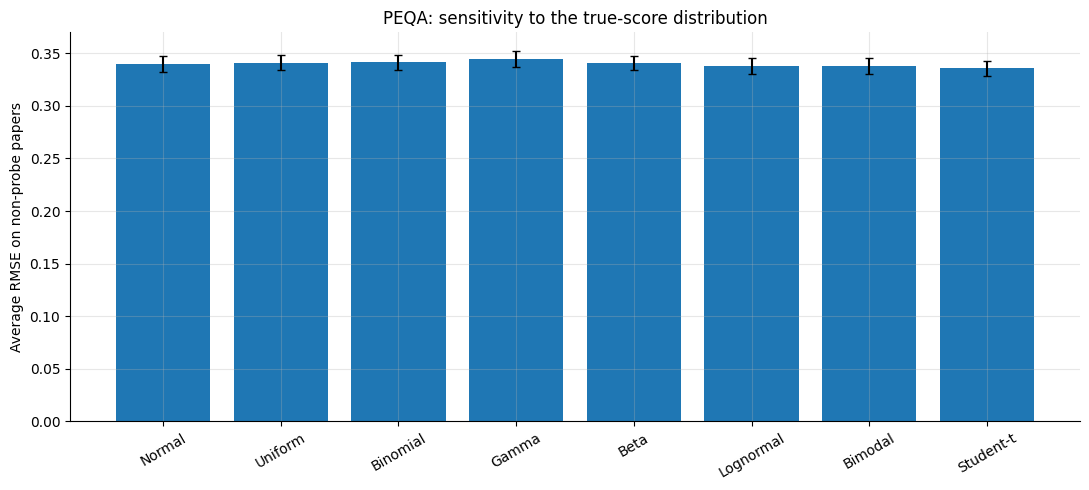

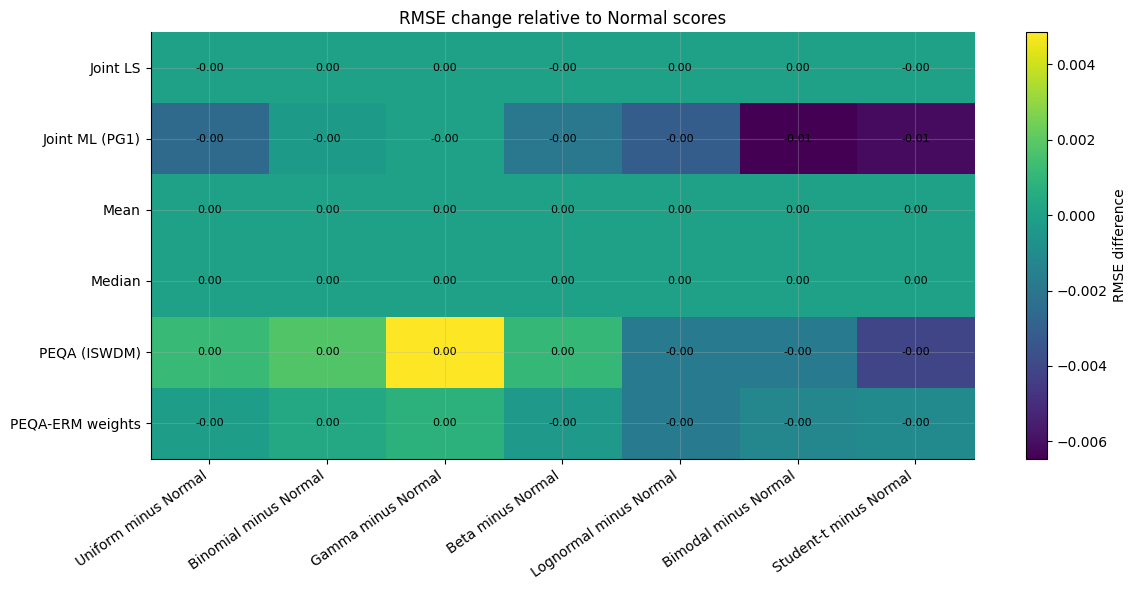

In [28]:
cfg_dist = SimConfig(adv_frac=0.0)
N_DIST_REPS = REPS_SWEEP

DIST_NAMES = [
    "Normal",
    "Uniform",
    "Binomial",
    "Gamma",
    "Beta",
    "Lognormal",
    "Bimodal",
    "Student-t"
]

SCORE_MAX = 10.0


def draw_true_scores(cfg, rng, distribution):
    """Draw scores with target theoretical mean and SD where specified."""

    mu = cfg.mu
    sd = cfg.sd_true
    n = cfg.n

    if distribution == "Normal":
        return rng.normal(mu, sd, n)

    elif distribution == "Uniform":
        half_width = np.sqrt(3) * sd
        return rng.uniform(mu - half_width, mu + half_width, n)

    elif distribution == "Binomial":
        # A Binomial(10, 0.6), centered and scaled to mean mu and SD sd.
        # With the default settings, the resulting scores stay within 0-10.
        trials = 10
        p = 0.6
        x = rng.binomial(trials, p, n)
        bin_sd = np.sqrt(trials * p * (1 - p))
        return mu + sd * (x - trials * p) / bin_sd

    elif distribution == "Gamma":
        # Gamma shape and scale chosen for mean mu and SD sd.
        shape = (mu / sd) ** 2
        scale = sd ** 2 / mu
        return rng.gamma(shape, scale, n)

    elif distribution == "Beta":
        # Beta distribution scaled to [0, 10], matching target mean and SD.
        m = mu / SCORE_MAX
        v = (sd / SCORE_MAX) ** 2
        concentration = m * (1 - m) / v - 1

        if concentration <= 0:
            raise ValueError(
                "The requested mean and SD are not feasible "
                "for this scaled Beta distribution."
            )

        a = m * concentration
        b = (1 - m) * concentration
        return SCORE_MAX * rng.beta(a, b, n)

    elif distribution == "Lognormal":
        # Lognormal parameters chosen for arithmetic mean mu and SD sd.
        log_var = np.log(1 + (sd / mu) ** 2)
        log_sd = np.sqrt(log_var)
        log_mean = np.log(mu) - log_var / 2
        return rng.lognormal(log_mean, log_sd, n)

    elif distribution == "Bimodal":
        # Equal mixture around mu, with target variance:
        # between-mode variance + within-mode variance = sd**2.
        separation = 0.8 * sd
        within_sd = np.sqrt(sd**2 - separation**2)
        centers = np.where(
            rng.random(n) < 0.5,
            mu - separation,
            mu + separation
        )
        return centers + rng.normal(0, within_sd, n)

    elif distribution == "Student-t":
        # Heavy-tailed t distribution with 3 degrees of freedom.
        # Its theoretical variance is 3 before standardization.
        df = 3
        return mu + sd * rng.standard_t(df, n) / np.sqrt(df / (df - 2))

    else:
        raise ValueError(f"Unknown distribution: {distribution}")


rows = []
score_checks = []

for rep in range(N_DIST_REPS):

    # Generate one shared grading environment for this repetition:
    # assignment, grader biases, reliabilities and random noise.
    # Reusing these lets us compare distributions under the same conditions.
    rng_world = np.random.default_rng(SEED + 90000 + rep)

    A, is_probe = make_assignment(
        cfg_dist.n, cfg_dist.K, cfg_dist.n_probes, rng_world
    )
    bias, tau, adv = generate_population(cfg_dist, rng_world)
    z = rng_world.standard_normal((cfg_dist.n, cfg_dist.n))

    for d_idx, distribution in enumerate(DIST_NAMES):

        # Separate score-generation stream for each distribution.
        rng_score = np.random.default_rng(
            SEED + 1000000 + rep * len(DIST_NAMES) + d_idx
        )

        y = draw_true_scores(cfg_dist, rng_score, distribution)
        Y = build_reports(y, A, bias, tau, z)

        rd = Round(
            cfg_dist, y, A, is_probe, Y,
            bias=bias, tau=tau, adv=adv
        )

        results = evaluate_round(rd)

        for method, metrics in results.items():
            rows.append({
                "distribution": distribution,
                "rep": rep,
                "rule": method,
                **metrics
            })

        score_checks.append({
            "distribution": distribution,
            "mean": y.mean(),
            "sd": y.std(ddof=1),
            "minimum": y.min(),
            "maximum": y.max()
        })


# ---------------------------------------------------------
# Summarise recovery RMSE on non-probe papers
# ---------------------------------------------------------
results_df = pd.DataFrame(rows)

summary = (
    results_df.groupby(["distribution", "rule"])["rmse"]
    .agg(["mean", "std", "count"])
    .reset_index()
)
summary["sem"] = summary["std"] / np.sqrt(summary["count"])

# Mean RMSE for each method under each distribution.
rmse_table = summary.pivot(
    index="rule", columns="distribution", values="mean"
).reindex(columns=DIST_NAMES)

print("Average RMSE on non-probe papers (lower is better):")
display(rmse_table.round(3))

# Difference from the Normal baseline.
delta_table = rmse_table.drop(columns="Normal").subtract(
    rmse_table["Normal"], axis=0
)
delta_table.columns = [f"{name} minus Normal" for name in delta_table.columns]

print("Change in RMSE compared with Normal scores:")
display(delta_table.round(3))

# Summarise the actual generated score distributions.
print("Sample mean, SD and range averaged over repetitions:")
score_summary = (
    pd.DataFrame(score_checks)
    .groupby("distribution")[["mean", "sd", "minimum", "maximum"]]
    .mean()
    .reindex(DIST_NAMES)
)
display(score_summary.round(3))


# ---------------------------------------------------------
# Plot 1: PEQA RMSE under each distribution
# ---------------------------------------------------------
peqa_name = "PEQA (ISWDM)"
peqa = summary[summary["rule"] == peqa_name].set_index("distribution")
peqa = peqa.reindex(DIST_NAMES)

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(
    DIST_NAMES,
    peqa["mean"],
    yerr=peqa["sem"],
    capsize=3
)
ax.set_ylabel("Average RMSE on non-probe papers")
ax.set_title("PEQA: sensitivity to the true-score distribution")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# Plot 2: How each method's RMSE changes relative to Normal
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))

data = delta_table.to_numpy()
im = ax.imshow(data, aspect="auto")

ax.set_xticks(range(len(delta_table.columns)))
ax.set_xticklabels(delta_table.columns, rotation=35, ha="right")
ax.set_yticks(range(len(delta_table.index)))
ax.set_yticklabels(delta_table.index)
ax.set_title("RMSE change relative to Normal scores")
fig.colorbar(im, ax=ax, label="RMSE difference")

for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        ax.text(j, i, f"{data[i, j]:.2f}", ha="center", va="center", fontsize=8)

plt.tight_layout()
plt.show()